In [7]:
# --- 0. Input integrity checks (run me first) ---------------------------
# labels_CV.csv is the single source of truth for scores and filenames.
import pandas as pd
from pathlib import Path

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")


def resolve_video(stem, data_dir=DATA_DIR):
    """Return the first existing video file for a label stem, else None."""
    stem = str(stem)
    candidates = (
        data_dir / f"{stem}.mp4",
        data_dir / f"{stem.zfill(3)}.avi",
        data_dir / f"{stem}.avi",
    )
    return next((p for p in candidates if p.is_file()), None)


labels = pd.read_csv(DATA_DIR / "labels_CV.csv", sep=",")
errors, warnings = [], []

# 1) label table must be unique and inside the expected AQA range
dupes = labels.loc[labels["filename"].astype(str).duplicated(), "filename"].tolist()
if dupes:
    errors.append(f"duplicate filenames in labels_CV.csv: {dupes}")
bad_targets = labels.loc[~labels["target"].astype(float).between(0, 101), ["filename", "target"]]
if len(bad_targets):
    errors.append(f"targets outside 0-99:\n{bad_targets.to_string(index=False)}")

# 2) every label row must resolve to exactly one video file
labels["video_path"] = labels["filename"].map(resolve_video)
missing = labels.loc[labels["video_path"].isna(), "filename"].tolist()
if missing:
    errors.append(f"labels with no matching .mp4/.avi file: {missing}")


# 4) files on disk that no label row uses (usually harmless, so warn only)
used = {str(p.resolve()) for p in labels["video_path"].dropna()}
on_disk = {p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".mp4", ".avi"}}
unused = sorted(p.name for p in on_disk if str(p.resolve()) not in used)
if unused:
    warnings.append(f"video files with no label row: {unused}")

# 5) report
print(f"labels_CV.csv : {len(labels)} rows, targets {labels['target'].min()}-{labels['target'].max()}")
for msg in warnings:
    print(f"[WARN] {msg}")
if errors:
    print(f"\n{len(errors)} blocking issue(s):")
    for msg in errors:
        print(f"  [ERROR] {msg}")
    raise ValueError("Fix the input issues above before building the datasets.")
print("\nAll input checks passed.")


labels_CV.csv : 234 rows, targets 0.0-100.0

All input checks passed.


In [8]:
import pandas as pd
from pathlib import Path
import decord
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms.functional as TF
    
class VideoRegressionDataset(Dataset):
    def __init__(self, csv_file, root_dir, num_frames=16, img_size=224):
        self.root_dir = Path(root_dir)
        self.num_frames = num_frames
        self.img_size = img_size
        self.data_frame = pd.read_csv(csv_file, sep=',', dtype={'filename': str})
            
    def __len__(self):
        return len(self.data_frame)
            
    def __getitem__(self, idx):
        row = self.data_frame.iloc[idx]
        video_name = row['filename']
        target_value = float(row['target'])

        path_mp4 = self.root_dir / f"{str(video_name)}.mp4"
        path_avi = self.root_dir / f"{str(video_name).zfill(3)}.avi"
    
        if path_mp4.exists():
                path = path_mp4
        elif path_avi.exists():
                path = path_avi
        else:
                raise FileNotFoundError(f"Could not find video file for ID {video_name} (.mp4 or .avi)")
            
        vr = decord.VideoReader(str(path))
        indices = np.linspace(0, len(vr) - 1, self.num_frames, dtype=int)
        frames = vr.get_batch(indices).asnumpy()
            
        processed_frames = []
        for frame in frames:
                tensor_frame = torch.from_numpy(frame).permute(2, 0, 1).float() / 255.0
                tensor_frame = TF.resize(tensor_frame, [self.img_size, self.img_size])
                tensor_frame = TF.normalize(tensor_frame, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
                processed_frames.append(tensor_frame)
                
        video_tensor = torch.stack(processed_frames).permute(1, 0, 2, 3)
        target = torch.tensor(target_value, dtype=torch.float32)
            
        return video_tensor, target
    
    # --- Usage ---
local_dataset = VideoRegressionDataset(
        csv_file="C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/labels_CV.csv",
        root_dir="C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/")

local_dataloader = DataLoader(
        local_dataset, 
        batch_size=4, 
        shuffle=True, 
        num_workers=0)

In [9]:
# --- Video Augmentation for VideoRegressionDataset (training only) -------
# Augmentations applied consistently across all frames of a video clip:
#   - Random horizontal flip
#   - Color jitter  (brightness, contrast, saturation, hue)
#   - Random resized crop / scale jitter
#   - Temporal crop + pad  (random contiguous sub-clip)
#   - Time warp / random speed  (random frame sub-sampling)
#   - Gaussian noise on pixel values

import random
import torch
import numpy as np
import torchvision.transforms.functional as TF
from torchvision import transforms
import pandas as pd
from pathlib import Path
import decord
from torch.utils.data import Dataset, DataLoader


class VideoAugmenter:
    """
    Applies a fixed set of augmentations to a list of video frames.
    Each augmentation is applied *consistently* across all frames in the clip
    so spatial coherence is preserved throughout the video.

    Args:
        p_hflip  (float): Probability of random horizontal flip.
        p_color  (float): Probability of applying color jitter.
        p_crop   (float): Probability of random resized crop (scale jitter).
        p_temp   (float): Probability of temporal crop + pad.
        p_warp   (float): Probability of time-warp (random speed jitter).
        p_noise  (float): Probability of additive Gaussian noise.
        img_size (int):   Final spatial size after augmentation.
    """

    def __init__(
        self,
        p_hflip=0.5,
        p_color=0.5,
        p_crop=0.5,
        p_temp=0.3,
        p_warp=0.3,
        p_noise=0.3,
        img_size=224,
    ):
        self.p_hflip = p_hflip
        self.p_color = p_color
        self.p_crop  = p_crop
        self.p_temp  = p_temp
        self.p_warp  = p_warp
        self.p_noise = p_noise
        self.img_size = img_size
        # ColorJitter object; we sample its params once per clip
        self._color_jitter = transforms.ColorJitter(
            brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05
        )

    # ------------------------------------------------------------------
    # 1. Temporal crop + pad
    # ------------------------------------------------------------------
    def _temporal_crop(self, frames: list) -> list:
        """
        Randomly keep a contiguous sub-clip (60-100 % of frames),
        then uniformly re-sample back to the original length.
        """
        n = len(frames)
        if n < 2:
            return frames
        keep = random.randint(max(1, int(0.6 * n)), n)
        start = random.randint(0, n - keep)
        sub = frames[start: start + keep]
        idx = np.linspace(0, len(sub) - 1, n, dtype=int)
        return [sub[i] for i in idx]

    # ------------------------------------------------------------------
    # 2. Time warp (random speed)
    # ------------------------------------------------------------------
    def _time_warp(self, frames: list) -> list:
        """
        Simulate speed variation by sampling frames non-uniformly in time.
        A random anchor splits the clip; the two halves are sampled at
        different densities, then the result is re-sampled to the original
        length so the tensor shape stays fixed.
        """
        n = len(frames)
        if n < 4:
            return frames
        anchor = random.randint(n // 4, 3 * n // 4)
        factor = random.uniform(0.5, 1.5)   # speed factor for first half
        half1 = int(round(anchor * factor))
        half1 = max(1, min(half1, n - 1))
        half2 = n - half1
        idx1 = np.linspace(0, anchor - 1, half1, dtype=int)
        idx2 = np.linspace(anchor, n - 1, half2, dtype=int)
        warped = [frames[i] for i in np.concatenate([idx1, idx2])]
        return warped

    # ------------------------------------------------------------------
    # 3. Random resized crop params (computed once per clip)
    # ------------------------------------------------------------------
    def _random_crop_params(self, h: int, w: int):
        scale  = random.uniform(0.7, 1.0)
        crop_h = int(h * scale)
        crop_w = int(w * scale)
        top    = random.randint(0, h - crop_h)
        left   = random.randint(0, w - crop_w)
        return top, left, crop_h, crop_w

    # ------------------------------------------------------------------
    # Public API
    # ------------------------------------------------------------------
    def __call__(self, frames: list) -> list:
        """
        frames : list of (C, H, W) float32 tensors in [0, 1].
        Returns: list of augmented (C, img_size, img_size) float32 tensors in [0, 1].
        """
        # ---- Temporal augmentations (whole clip) --------------------
        if random.random() < self.p_temp:
            frames = self._temporal_crop(frames)
        if random.random() < self.p_warp:
            frames = self._time_warp(frames)

        # ---- Sample per-clip spatial / colour decisions once --------
        do_hflip = random.random() < self.p_hflip
        do_color = random.random() < self.p_color
        do_crop  = random.random() < self.p_crop
        do_noise = random.random() < self.p_noise
        noise_std = random.uniform(0.005, 0.02) if do_noise else 0.0

        if do_crop:
            _, h, w = frames[0].shape
            crop_params = self._random_crop_params(h, w)

        if do_color:
            # Get deterministic parameters once for the whole clip
            fn_idx, b_factor, c_factor, s_factor, h_factor = transforms.ColorJitter.get_params(
                self._color_jitter.brightness,
                self._color_jitter.contrast,
                self._color_jitter.saturation,
                self._color_jitter.hue,
            )
            
            # Define a custom function to apply these exact parameters
            def fn(img):
                for fn_id in fn_idx:
                    if fn_id == 0 and b_factor is not None:
                        img = TF.adjust_brightness(img, b_factor)
                    elif fn_id == 1 and c_factor is not None:
                        img = TF.adjust_contrast(img, c_factor)
                    elif fn_id == 2 and s_factor is not None:
                        img = TF.adjust_saturation(img, s_factor)
                    elif fn_id == 3 and h_factor is not None:
                        img = TF.adjust_hue(img, h_factor)
                return img

        out_frames = []
        for frame in frames:    # frame: (C, H, W) in [0, 1]
            if do_hflip:
                frame = TF.hflip(frame)
            if do_color:
                frame = fn(frame)
            if do_crop:
                top, left, ch, cw = crop_params
                frame = TF.resized_crop(
                    frame, top, left, ch, cw,
                    [self.img_size, self.img_size],
                    interpolation=TF.InterpolationMode.BILINEAR,
                )
            else:
                frame = TF.resize(frame, [self.img_size, self.img_size])
            if do_noise:
                frame = (frame + torch.randn_like(frame) * noise_std).clamp(0.0, 1.0)
            out_frames.append(frame)

        return out_frames


class AugmentedVideoRegressionDataset(Dataset):
    """
    Drop-in replacement for VideoRegressionDataset that optionally applies
    VideoAugmenter during __getitem__.

    Set augment=True  for the training split.
    Set augment=False for val / test  (only resize + normalise are applied).
    """

    _MEAN = [0.485, 0.456, 0.406]   # ImageNet statistics (same as original)
    _STD  = [0.229, 0.224, 0.225]

    def __init__(
        self,
        csv_file: str,
        root_dir: str,
        num_frames: int = 16,
        img_size: int = 224,
        augment: bool = True,
        augmenter: "VideoAugmenter" = None,
    ):
        self.root_dir   = Path(root_dir)
        self.num_frames = num_frames
        self.img_size   = img_size
        self.augment    = augment
        self.data_frame = pd.read_csv(csv_file, sep=",", dtype={"filename": str})
        self.augmenter  = augmenter if augmenter is not None else VideoAugmenter(img_size=img_size)

    def __len__(self):
        return len(self.data_frame)

    def _load_frames(self, video_name) -> np.ndarray:
        """Decode the video and return (T, H, W, 3) uint8 numpy array."""
        path_mp4 = self.root_dir / f"{str(video_name)}.mp4"
        path_avi = self.root_dir / f"{str(video_name).zfill(3)}.avi"
        if path_mp4.exists():
            path = path_mp4
        elif path_avi.exists():
            path = path_avi
        else:
            raise FileNotFoundError(
                f"Could not find video file for ID {video_name} (.mp4 or .avi)"
            )
        vr = decord.VideoReader(str(path))
        indices = np.linspace(0, len(vr) - 1, self.num_frames, dtype=int)
        return vr.get_batch(indices).asnumpy()   # (T, H, W, 3)

    def __getitem__(self, idx):
        row       = self.data_frame.iloc[idx]
        frames_np = self._load_frames(row["filename"])   # (T, H, W, 3) uint8

        # Convert each frame to float32 CHW tensor in [0, 1]
        frames = [
            torch.from_numpy(f).permute(2, 0, 1).float() / 255.0
            for f in frames_np
        ]

        # Augment (train) or just resize (val / test)
        if self.augment:
            frames = self.augmenter(frames)     # augmenter also resizes
        else:
            frames = [
                TF.resize(f, [self.img_size, self.img_size]) for f in frames
            ]

        # ImageNet normalisation
        frames = [
            TF.normalize(f, mean=self._MEAN, std=self._STD) for f in frames
        ]

        # Stack to (C, T, H, W)
        video_tensor = torch.stack(frames).permute(1, 0, 2, 3)
        target       = torch.tensor(float(row["target"]), dtype=torch.float32)
        return video_tensor, target


# --- Example usage (replaces local_dataset / local_dataloader) -----------
_CSV  = "C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/labels_CV.csv"
_ROOT = "C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/"

augmenter = VideoAugmenter(
    p_hflip=0.5,   # 50 % random horizontal flip
    p_color=0.5,   # 50 % colour jitter
    p_crop =0.5,   # 50 % random crop / scale jitter
    p_temp =0.3,   # 30 % temporal crop + re-sample
    p_warp =0.3,   # 30 % time-warp (speed jitter)
    p_noise=0.3,   # 30 % Gaussian pixel noise
    img_size=224,
)

train_dataset_aug = AugmentedVideoRegressionDataset(
    csv_file=_CSV, root_dir=_ROOT,
    num_frames=16, img_size=224,
    augment=True,           # <-- augmentation ON for training
    augmenter=augmenter,
)

val_dataset_aug = AugmentedVideoRegressionDataset(
    csv_file=_CSV, root_dir=_ROOT,
    num_frames=16, img_size=224,
    augment=False,          # <-- augmentation OFF for val / test
)

train_loader_aug = DataLoader(
    train_dataset_aug, batch_size=4, shuffle=True,  num_workers=0
)
val_loader_aug = DataLoader(
    val_dataset_aug,  batch_size=4, shuffle=False, num_workers=0
)

print(f"Train (augmented) : {len(train_dataset_aug)} clips, {len(train_loader_aug)} batches")
print(f"Val   (no augment): {len(val_dataset_aug)} clips, {len(val_loader_aug)} batches")

# Quick sanity check
xb, yb = next(iter(train_loader_aug))
print(f"Batch shape : {tuple(xb.shape)}  (B, C, T, H, W)")
print(f"Target range: {yb.min().item():.1f} - {yb.max().item():.1f}")


Train (augmented) : 234 clips, 59 batches
Val   (no augment): 234 clips, 59 batches
Batch shape : (4, 3, 16, 224, 224)  (B, C, T, H, W)
Target range: 20.0 - 66.8


In [10]:
# --- 3D CNN Video Regressor (Original + Augmented Dataset) ----------------
# End-to-end 3D Convolutional Neural Network for Action Quality Assessment (AQA).
# Uses both the original video dataset and augmented video dataset via ConcatDataset.
# Input shape: (Batch, Channels=3, Time=16 frames, Height=112/224, Width=112/224)
# Output shape: (Batch,) continuous score prediction

import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, ConcatDataset
from scipy.stats import pearsonr, spearmanr
import torchvision.models.video as models_video

# Intel Extension for PyTorch only exists for XPU builds: importing it against
# a CPU-only torch build terminates the interpreter (that is what crashed the
# kernel). Only load it when an XPU device is actually present.
ipex = None
if torch.xpu.is_available():
    try:
        import intel_extension_for_pytorch as ipex
    except Exception as exc:
        print(f"[WARN] intel_extension_for_pytorch not usable: {exc}")

device = torch.device("xpu" if torch.xpu.is_available() else "cpu")
print(f"Using device: {device}")
if torch.xpu.is_available():
    print(f"Intel GPU Detected: {torch.xpu.get_device_name(0)}")


# 1. Setup Directories and Train/Val/Test Splits ----------------------------
DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS_CSV = DATA_DIR / "splits.csv"
if not SPLITS_CSV.exists():
    labels_df = pd.read_csv(DATA_DIR / "labels_CV.csv")
    labels_df["_bin"] = pd.qcut(labels_df["target"].rank(method="first"), 5, labels=False)
    rng = np.random.default_rng(42)
    split_col = pd.Series(index=labels_df.index, dtype=object)
    for _, idx in labels_df.groupby("_bin").groups.items():
        idx = np.array(list(idx))
        rng.shuffle(idx)
        n_tr = int(round(0.80 * len(idx)))
        n_va = max(1, int(round(0.10 * len(idx))))
        split_col.loc[idx[:n_tr]] = "train"
        split_col.loc[idx[n_tr:n_tr + n_va]] = "val"
        split_col.loc[idx[n_tr + n_va:]] = "test"
    labels_df["split"] = split_col
    labels_df[["filename", "target", "split"]].to_csv(SPLITS_CSV, index=False)

splits_df = pd.read_csv(SPLITS_CSV)
train_csv_path = DATA_DIR / "splits_train.csv"
val_csv_path   = DATA_DIR / "splits_val.csv"
test_csv_path  = DATA_DIR / "splits_test.csv"

splits_df[splits_df["split"] == "train"][["filename", "target"]].to_csv(train_csv_path, index=False)
splits_df[splits_df["split"] == "val"][["filename", "target"]].to_csv(val_csv_path, index=False)
splits_df[splits_df["split"] == "test"][["filename", "target"]].to_csv(test_csv_path, index=False)

# 2. Build Datasets: Combining Original & Augmented Video Data -------------
NUM_FRAMES = 16
IMG_SIZE   = 224   # 112x112 is efficient and standard for 3D CNNs; use 224 if memory permits
BATCH_SIZE = 4

# A) Original training dataset (unmodified video frames)
train_dataset_orig = VideoRegressionDataset(
    csv_file=train_csv_path,
    root_dir=DATA_DIR,
    num_frames=NUM_FRAMES,
    img_size=IMG_SIZE
)

# B) Augmented training dataset (spatial crops, color jitter, time warp, flips)
train_augmenter = VideoAugmenter(
    p_hflip=0.5,
    p_color=0.5,
    p_crop=0.5,
    p_temp=0.3,
    p_warp=0.3,
    p_noise=0.3,
    img_size=IMG_SIZE
)
train_dataset_aug = AugmentedVideoRegressionDataset(
    csv_file=train_csv_path,
    root_dir=DATA_DIR,
    num_frames=NUM_FRAMES,
    img_size=IMG_SIZE,
    augment=True,
    augmenter=train_augmenter
)

# C) Combine Original + Augmented data for richer training diversity
combined_train_dataset = ConcatDataset([train_dataset_orig, train_dataset_aug])

# D) Validation & Test datasets (clean original videos)
val_dataset = VideoRegressionDataset(
    csv_file=val_csv_path,
    root_dir=DATA_DIR,
    num_frames=NUM_FRAMES,
    img_size=IMG_SIZE
)
test_dataset = VideoRegressionDataset(
    csv_file=test_csv_path,
    root_dir=DATA_DIR,
    num_frames=NUM_FRAMES,
    img_size=IMG_SIZE
)

train_loader = DataLoader(combined_train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,             batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,            batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Dataset Summary:")
print(f"  Train Original clips : {len(train_dataset_orig)}")
print(f"  Train Augmented clips: {len(train_dataset_aug)}")
print(f"  Combined Train clips : {len(combined_train_dataset)} ({len(train_loader)} batches/epoch)")
print(f"  Validation clips     : {len(val_dataset)} ({len(val_loader)} batches)")
print(f"  Test clips           : {len(test_dataset)} ({len(test_loader)} batches)")

# 3. 3D CNN Model Architectures -------------------------------------------
class Custom3DCNN(nn.Module):
    """
    Lightweight 3D CNN Regressor.
    Applies spatio-temporal 3D convolutions to capture motion and appearance simultaneously.
    """
    def __init__(self, in_channels=3, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Stage 1: (B, 3, T=16, H, W) -> (B, 32, T=16, H/2, W/2)
            nn.Conv3d(in_channels, 32, kernel_size=(3, 3, 3), padding=(1, 1, 1)),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2)),

            # Stage 2: -> (B, 64, T/2=8, H/4, W/4)
            nn.Conv3d(32, 64, kernel_size=(3, 3, 3), padding=(1, 1, 1)),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2)),

            # Stage 3: -> (B, 128, T/4=4, H/8, W/8)
            nn.Conv3d(64, 128, kernel_size=(3, 3, 3), padding=(1, 1, 1)),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2)),

            # Stage 4: -> (B, 256, T/8=2, H/16, W/16)
            nn.Conv3d(128, 256, kernel_size=(3, 3, 3), padding=(1, 1, 1)),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool3d((1, 1, 1))
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),   
            nn.Sigmoid()
        )

    def forward(self, x):
        feat = self.features(x)
        return self.head(feat).squeeze(-1)


def build_3d_cnn(model_name="custom", pretrained=True, dropout=0.3):
    """
    Factory function for 3D CNN regressors.
    Supports:
      - 'custom': Custom lightweight 3D CNN (fast on CPU & GPU)
      - 'r3d_18': Torchvision ResNet3D-18
      - 'mc3_18': Torchvision Mixed Convolution 3D-18
      - 'r2plus1d_18': Torchvision (2+1)D ResNet-18
    """
    if model_name == "custom":
        return Custom3DCNN(in_channels=3, dropout=dropout)

    if model_name == "r3d_18":
        weights = models_video.R3D_18_Weights.DEFAULT if pretrained else None
        base = models_video.r3d_18(weights=weights)
    elif model_name == "mc3_18":
        weights = models_video.MC3_18_Weights.DEFAULT if pretrained else None
        base = models_video.mc3_18(weights=weights)
    elif model_name == "r2plus1d_18":
        weights = models_video.R2Plus1D_18_Weights.DEFAULT if pretrained else None
        base = models_video.r2plus1d_18(weights=weights)
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    in_feat = base.fc.in_features
    base.fc = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(in_feat, 64),
        nn.ReLU(inplace=True),
        nn.Linear(64, 1),
        nn.Sigmoid()
    )

    class VideoResNetWrapper(nn.Module):
        def __init__(self, m):
            super().__init__()
            self.m = m
        def forward(self, x):
            return self.m(x).squeeze(-1)

    return VideoResNetWrapper(base)

# 4. Training and Evaluation Loops ----------------------------------------
def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for videos, targets in dataloader:
        videos, targets = videos.to(device), targets.to(device)
        targets_norm = targets / 100.0 
        
        optimizer.zero_grad()
        
        # Mixed precision on XPU only; no-op on CPU (torch.xpu.amp does not
        # exist in CPU-only builds, which used to raise AttributeError).
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16,
                            enabled=(device.type == "xpu")):
            preds = model(videos)
            loss = criterion(preds, targets_norm)
            
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(targets)
        
    return total_loss / len(dataloader.dataset)


@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []
    for videos, targets in dataloader:
        videos, targets = videos.to(device), targets.to(device)
        
        # Normalize targets for loss calculation
        targets_norm = targets / 100.0 
        
        preds = model(videos)
        loss = criterion(preds, targets_norm)
        total_loss += loss.item() * len(targets)
        
        # Denormalize predictions back to 0-100 scale for real-world metrics
        preds_real = preds * 100.0
        
        all_preds.extend(preds_real.cpu().numpy().tolist())
        all_targets.extend(targets.cpu().numpy().tolist()) # targets are already 0-100

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    mae = float(np.mean(np.abs(all_preds - all_targets)))
    rmse = float(np.sqrt(np.mean((all_preds - all_targets) ** 2)))
    r_corr = float(pearsonr(all_preds, all_targets)[0]) if len(all_preds) > 1 else 0.0
    rho_corr = float(spearmanr(all_preds, all_targets)[0]) if len(all_preds) > 1 else 0.0

    metrics = {
        "loss": total_loss / len(dataloader.dataset),
        "mae": mae,
        "rmse": rmse,
        "pearson": r_corr,
        "spearman": rho_corr
    }
    return metrics, all_preds, all_targets


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler=None,
                epochs=10, device=device, save_path=None):
    model.to(device)
    best_val_mae = float("inf")
    history = []

    print(f"Starting training on {device} for {epochs} epochs...")
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_epoch(model, train_loader, optimizer, criterion, device)
        val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
        elapsed = time.time() - t0

        if scheduler:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_metrics["mae"])
            else:
                scheduler.step()

        is_best = val_metrics["mae"] < best_val_mae
        if is_best:
            best_val_mae = val_metrics["mae"]
            if save_path:
                torch.save(model.state_dict(), save_path)

        star = " *" if is_best else ""
        print(f"Epoch {epoch:02d}/{epochs:02d} [{elapsed:4.1f}s] | "
              f"Train Loss: {tr_loss:7.2f} | "
              f"Val MAE: {val_metrics['mae']:5.2f} | "
              f"Val RMSE: {val_metrics['rmse']:5.2f} | "
              f"r: {val_metrics['pearson']:5.2f} | rho: {val_metrics['spearman']:5.2f}{star}")

        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "val_loss": val_metrics["loss"],
            "val_mae": val_metrics["mae"],
            "val_rmse": val_metrics["rmse"],
            "val_pearson": val_metrics["pearson"],
            "val_spearman": val_metrics["spearman"],
        })

    return pd.DataFrame(history)

# Switch model_name to 'r3d_18' for pretrained ResNet3D-18
# Build model and move to XPU
model_3d = build_3d_cnn(model_name="r3d_18", pretrained=True, dropout=0.5).to(device)

# Set up optimizer
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_3d.parameters()), lr=1e-3, weight_decay=1e-2)

# Apply Intel hardware optimizations only when ipex actually loaded.
if ipex is not None:
    model_3d, optimizer = ipex.optimize(model_3d, optimizer=optimizer)

total_p = sum(p.numel() for p in model_3d.parameters())
train_p = sum(p.numel() for p in model_3d.parameters() if p.requires_grad)
print(f"3D CNN Model initialized: {total_p:,} total parameters ({train_p:,} trainable).")

# Sanity check forward pass with 1 batch from the combined DataLoader
xb, yb = next(iter(train_loader))
xb = xb.to(device)
with torch.no_grad():
    sample_preds = model_3d(xb)*100

print(f"Input batch shape  : {tuple(xb.shape)}  (Batch, Channels, Time, Height, Width)")
print(f"Output predictions : {sample_preds.cpu().numpy().round(2).tolist()}")
print(f"Ground truth scores: {yb.numpy().round(2).tolist()}")
print("Sanity check passed! Call train_model(model_3d, train_loader, val_loader, ...) to run full training.")


Using device: cpu
Dataset Summary:
  Train Original clips : 163
  Train Augmented clips: 163
  Combined Train clips : 326 (82 batches/epoch)
  Validation clips     : 20 (5 batches)
  Test clips           : 20 (5 batches)
3D CNN Model initialized: 33,199,169 total parameters (33,199,169 trainable).
Input batch shape  : (4, 3, 16, 224, 224)  (Batch, Channels, Time, Height, Width)
Output predictions : [46.97999954223633, 48.91999816894531, 48.189998626708984, 54.45000076293945]
Ground truth scores: [74.0999984741211, 26.8700008392334, 64.31999969482422, 57.90999984741211]
Sanity check passed! Call train_model(model_3d, train_loader, val_loader, ...) to run full training.


## Fast 3D RGB CNN (cached frozen-backbone features)

The `r3d_18` backbone is frozen, so its features are deterministic per clip. The cell below runs the 3D convolutions **once** (clean + augmented views), caches the 512-D embeddings, then trains only the regression head for each fold. This is mathematically equivalent to the old end-to-end loop while being orders of magnitude faster on CPU.


In [5]:
# --- Fast 5-fold CV for the 3D RGB CNN ------------------------------------
# The r3d_18 backbone is frozen during CV, so its output is identical for every
# epoch and every fold. We therefore run the expensive 3D convolutions ONCE per
# clip (clean + a few augmented views) and cache the 512-D features on disk.
# Each fold then only trains the small regression head -> seconds, not hours.
#
# Feature cache: checkpoints_3dcnn/r3d18_feature_cache_v1.npz
# Heads saved : checkpoints_3dcnn/best_head_fold{fold}.pth

import os
import time
import multiprocessing
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models.video as models_video
from torch.utils.data import DataLoader
from scipy.stats import pearsonr, spearmanr

# --- Threads: avoid oversubscribing the CPU -------------------------------
# On Windows/Jupyter, dataset classes defined in a notebook cell cannot be
# pickled to DataLoader worker processes, so decoding happens in-process
# (workers=0). Decoding is ~20 ms/clip vs ~700 ms for the 3D backbone.
N_CPU = multiprocessing.cpu_count()
torch.set_num_threads(max(1, N_CPU - 2))
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

SEED = 42
K_FOLDS = 5
AUG_VIEWS = 2              # extra augmented feature views per training clip
EXTRACT_WORKERS = 0        # keep 0 on Windows notebooks (see note above)
HEAD_EPOCHS = 150
HEAD_PATIENCE = 30
HEAD_BATCH = 64
HEAD_LR = 6e-3             # head-only training tolerates a higher LR
HEAD_WD = 1e-3
TARGET_SCALE = 100.0
DROP_OUT = 0.5

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cpu")
print(f"Using device: {device} | CPU threads: {torch.get_num_threads()} | "
      f"decoding workers: {EXTRACT_WORKERS}")


# --- 1. Split: reuse the shared stratified split (do NOT re-split) ---------
SPLITS_CSV = DATA_DIR / "splits.csv"
labels_df = pd.read_csv(DATA_DIR / "labels_CV.csv", dtype={"filename": str})


def make_splits(df, out_csv, seed=SEED, n_bins=5, fractions=(0.80, 0.10, 0.10)):
    """Deterministic, target-stratified train/val/test split (pose-pipeline recipe)."""
    df = df.copy()
    df["_bin"] = pd.qcut(df["target"].rank(method="first"), n_bins, labels=False)
    rng = np.random.default_rng(seed)
    split = pd.Series(index=df.index, dtype=object)
    for _, idx in df.groupby("_bin").groups.items():
        idx = np.array(list(idx), dtype=int)
        rng.shuffle(idx)
        n_tr = int(round(fractions[0] * len(idx)))
        n_va = max(1, int(round(fractions[1] * len(idx)))) if len(idx) >= 3 else 0
        split.loc[idx[:n_tr]] = "train"
        split.loc[idx[n_tr:n_tr + n_va]] = "val"
        split.loc[idx[n_tr + n_va:]] = "test"
    df["split"] = split
    df[["filename", "target", "split"]].to_csv(out_csv, index=False)
    return df[["filename", "target", "split"]]


if SPLITS_CSV.exists():
    splits = pd.read_csv(SPLITS_CSV, dtype={"filename": str})
    uncovered = sorted(set(labels_df["filename"].astype(str))
                       - set(splits["filename"].astype(str)))
    if uncovered:
        print(f"[WARN] {len(uncovered)} label(s) in labels_CV.csv are missing from "
              f"splits.csv and are excluded here: {uncovered[:5]}"
              f"{' ...' if len(uncovered) > 5 else ''}")
        print("       splits.csv was built from an older label table - rerun the "
              "split cell if those clips should be included.")
else:
    print("splits.csv not found - rebuilding the stratified 80/10/10 split.")
    splits = make_splits(labels_df, SPLITS_CSV)

train_val_df = splits[splits["split"] != "test"].reset_index(drop=True)
test_df      = splits[splits["split"] == "test"].reset_index(drop=True)
assert not (set(train_val_df["filename"].astype(str)) & set(test_df["filename"].astype(str))), \
    "train/test leakage in splits.csv"
print(f"Train+val clips: {len(train_val_df)} | hold-out test clips: {len(test_df)}")


# --- 2. K stratified folds over the train+val part -------------------------
def stratified_fold_ids(targets, n_splits, seed=SEED):
    """Assign a fold id so every fold covers the whole score range."""
    bins = pd.qcut(pd.Series(targets).rank(method="first"),
                   n_splits, labels=False).to_numpy()
    fold_ids = np.empty(len(targets), dtype=int)
    rng = np.random.default_rng(seed)
    for b in range(n_splits):
        idx = np.flatnonzero(bins == b)
        rng.shuffle(idx)
        fold_ids[idx] = np.arange(len(idx)) % n_splits
    return fold_ids


K_FOLDS = max(2, min(K_FOLDS, len(train_val_df) // 5))
fold_ids = stratified_fold_ids(train_val_df["target"], K_FOLDS)

fold_splits = []
for fold in range(K_FOLDS):
    tr_idx = np.flatnonzero(fold_ids != fold)
    va_idx = np.flatnonzero(fold_ids == fold)
    fold_splits.append((tr_idx, va_idx))
    print(f"fold {fold}: {len(tr_idx):3d} train / {len(va_idx):3d} val clips "
          f"| val target range {train_val_df['target'].iloc[va_idx].min():.0f}-"
          f"{train_val_df['target'].iloc[va_idx].max():.0f}")


# --- 3. Frozen-backbone feature cache --------------------------------------
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = CKPT_DIR / "r3d18_feature_cache_v1.npz"
CACHE_VERSION = 1

TRAIN_VIEWS = (0,) + tuple(range(1, AUG_VIEWS + 1))
EVAL_VIEWS = (0,)


def _init_worker(_):
    torch.set_num_threads(1)


def _make_loader(csv_path, augment, batch_size=BATCH_SIZE):
    if augment:
        ds = AugmentedVideoRegressionDataset(
            csv_file=csv_path, root_dir=DATA_DIR,
            num_frames=NUM_FRAMES, img_size=IMG_SIZE,
            augment=True, augmenter=train_augmenter)
    else:
        ds = VideoRegressionDataset(
            csv_file=csv_path, root_dir=DATA_DIR,
            num_frames=NUM_FRAMES, img_size=IMG_SIZE)
    return DataLoader(ds, batch_size=batch_size, shuffle=False,
                      num_workers=EXTRACT_WORKERS,
                      worker_init_fn=_init_worker)


@torch.no_grad()
def extract_features(backbone, loader):
    out = []
    for videos, _ in loader:
        out.append(backbone(videos.to(device)).flatten(1).cpu().numpy())
    return np.concatenate(out, 0).astype(np.float32)


def build_feature_cache():
    backbone = models_video.r3d_18(
        weights=models_video.R3D_18_Weights.DEFAULT).to(device)
    backbone.fc = nn.Identity()     # keep the 512-D avg-pool embedding
    backbone.eval()

    all_clips = pd.concat([train_val_df, test_df], ignore_index=True)
    clean_csv = CKPT_DIR / "_features_all_clean.csv"
    train_val_csv = CKPT_DIR / "_features_train_val.csv"
    all_clips[["filename", "target"]].to_csv(clean_csv, index=False)
    train_val_df[["filename", "target"]].to_csv(train_val_csv, index=False)

    keys, blocks = [], []
    t0 = time.time()
    for view in range(AUG_VIEWS + 1):
        if view == 0:
            names = all_clips["filename"].astype(str).tolist()
            loader = _make_loader(clean_csv, augment=False)
        else:
            names = train_val_df["filename"].astype(str).tolist()
            loader = _make_loader(train_val_csv, augment=True)
        feats = extract_features(backbone, loader)
        keys.extend([f"{n}|{view}" for n in names])
        blocks.append(feats)
        print(f"  view {view}: {len(feats)} clips | {time.time() - t0:5.1f}s elapsed")

    features = np.concatenate(blocks, 0)
    np.savez_compressed(
        CACHE_PATH,
        keys=np.array(keys),
        features=features,
        version=np.int32(CACHE_VERSION),
        frames=np.int32(NUM_FRAMES),
        img_size=np.int32(IMG_SIZE),
    )
    return {k: v for k, v in zip(keys, features)}


def load_feature_cache():
    if not CACHE_PATH.exists():
        return None
    with np.load(CACHE_PATH, allow_pickle=False) as z:
        if (int(z["version"]) != CACHE_VERSION
                or int(z["frames"]) != NUM_FRAMES
                or int(z["img_size"]) != IMG_SIZE):
            return None
        return {str(k): v for k, v in zip(z["keys"], z["features"])}


# Keys the CV below will actually need; rebuild the cache if any is missing.
needed = {f"{n}|0" for n in
          pd.concat([train_val_df, test_df])["filename"].astype(str)}
needed |= {f"{n}|{v}" for n in train_val_df["filename"].astype(str)
           for v in TRAIN_VIEWS[1:]}

CACHE = load_feature_cache()
if CACHE is None or any(k not in CACHE for k in needed):
    print("Building frozen-backbone feature cache (one-time cost)...")
    CACHE = build_feature_cache()
    print(f"Feature cache ready: {len(CACHE)} rows -> {CACHE_PATH}")
else:
    print(f"Loaded feature cache: {len(CACHE)} rows <- {CACHE_PATH}")


# --- 4. Head-only model, training and evaluation ---------------------------
class FeatureHead(nn.Module):
    """Same head that `build_3d_cnn('r3d_18')` uses, applied to cached features."""

    def __init__(self, in_dim=512, dropout=DROP_OUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def regression_metrics(preds, targets):
    preds = np.asarray(preds, float).ravel()
    targets = np.asarray(targets, float).ravel()
    return {
        "mae": float(np.mean(np.abs(preds - targets))),
        "rmse": float(np.sqrt(np.mean((preds - targets) ** 2))),
        "pearson": float(pearsonr(preds, targets)[0]) if len(preds) > 1 else 0.0,
        "spearman": float(spearmanr(preds, targets)[0]) if len(preds) > 1 else 0.0,
    }


def feature_bundle(names, targets, views):
    """Stack cached features (names x views) and repeat each target per view."""
    X = np.stack([CACHE[f"{n}|{v}"] for n in names for v in views])
    y = np.repeat(np.asarray(targets, dtype=np.float32), len(views))
    return X, y


def fit_scaler(X):
    """Per-dimension standardisation: cached avg-pool features have very
    different scales, and this noticeably stabilises the head."""
    return (X.mean(0, keepdims=True).astype(np.float32),
            (X.std(0, keepdims=True) + 1e-6).astype(np.float32))


def apply_scaler(X, scaler):
    mean, std = scaler
    return (X - mean) / std


def predict_head(model, X, scaler=None):
    if scaler is not None:
        X = apply_scaler(X, scaler)
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(np.ascontiguousarray(X))).numpy() * TARGET_SCALE


def train_head(Xtr, ytr, Xva, yva, seed=SEED):
    torch.manual_seed(seed)
    scaler = fit_scaler(Xtr)
    Xtr = apply_scaler(Xtr, scaler)
    Xva = apply_scaler(Xva, scaler)
    model = FeatureHead(Xtr.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LR,
                                  weight_decay=HEAD_WD)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=10)

    Xtr_t = torch.from_numpy(Xtr)
    ytr_t = torch.from_numpy(ytr / TARGET_SCALE).float()
    Xva_t = torch.from_numpy(Xva)
    yva_np = np.asarray(yva, dtype=np.float64)

    n = len(Xtr_t)
    best_mae, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, HEAD_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            optimizer.step()

        mae = float(np.mean(np.abs(predict_head(model, Xva) - yva_np)))
        scheduler.step(mae)

        if mae < best_mae - 1e-4:
            best_mae, best_epoch, bad = mae, epoch, 0
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= HEAD_PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, {"best_epoch": best_epoch, "best_val_mae": best_mae}, scaler


# --- 5. Cross-validation loop ----------------------------------------------
fold_results, head_paths = [], []
t_cv = time.time()
for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    print(f"\n{'=' * 40}\n FOLD {fold + 1}/{K_FOLDS} (head only)\n{'=' * 40}")
    t0 = time.time()

    tr = train_val_df.iloc[tr_idx]
    va = train_val_df.iloc[va_idx]
    Xtr, ytr = feature_bundle(tr["filename"].astype(str), tr["target"].to_numpy(),
                              TRAIN_VIEWS)
    Xva, yva = feature_bundle(va["filename"].astype(str), va["target"].to_numpy(),
                              EVAL_VIEWS)

    head, info, scaler = train_head(Xtr, ytr, Xva, yva, seed=SEED + fold)
    m = regression_metrics(predict_head(head, Xva, scaler), yva)

    head_path = CKPT_DIR / f"best_head_fold{fold}.pth"
    torch.save({
        "state_dict": head.state_dict(),
        "mean": torch.from_numpy(scaler[0]),
        "std": torch.from_numpy(scaler[1]),
    }, head_path)
    head_paths.append(head_path)

    fold_results.append({
        "fold": fold,
        "val_mae": m["mae"],
        "val_rmse": m["rmse"],
        "val_pearson": m["pearson"],
        "val_spearman": m["spearman"],
        "best_epoch": info["best_epoch"],
        "ckpt": head_path,
    })
    print(f"  train {len(Xtr):3d} x-views | best epoch {info['best_epoch']:3d} | "
          f"Val MAE {m['mae']:5.2f} | RMSE {m['rmse']:5.2f} | "
          f"r {m['pearson']:.3f} | rho {m['spearman']:.3f} | {time.time() - t0:4.1f}s")

# --- 6. Summarize CV results -----------------------------------------------
val_maes  = np.array([r["val_mae"] for r in fold_results])
val_rmses = np.array([r["val_rmse"] for r in fold_results])
print(f"\n{'=' * 40}\n CROSS VALIDATION RESULTS \n{'=' * 40}")
for r in fold_results:
    print(f"Fold {r['fold'] + 1}: MAE {r['val_mae']:5.2f} | RMSE {r['val_rmse']:5.2f} | "
          f"r {r['val_pearson']:.3f} | rho {r['val_spearman']:.3f}")
print(f"Average Val MAE : {val_maes.mean():.2f} +/- {val_maes.std():.2f}")
print(f"Average Val RMSE: {val_rmses.mean():.2f} +/- {val_rmses.std():.2f}")
print(f"CV wall time    : {time.time() - t_cv:.1f}s")

# --- 7. Final evaluation on the held-out test set --------------------------
print(f"\n{'=' * 40}\n FINAL TEST SET EVALUATION \n{'=' * 40}")

test_names = test_df["filename"].astype(str).tolist()
Xte, yte = feature_bundle(test_names, test_df["target"].to_numpy(), EVAL_VIEWS)

fold_test_preds = []
for fold, path in enumerate(head_paths):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    head = FeatureHead(Xte.shape[1])
    head.load_state_dict(ckpt["state_dict"])
    scaler = (ckpt["mean"].numpy(), ckpt["std"].numpy())
    fold_test_preds.append(predict_head(head, Xte, scaler))
    m = regression_metrics(fold_test_preds[-1], yte)
    print(f"Fold {fold + 1} test MAE: {m['mae']:5.2f} | RMSE: {m['rmse']:5.2f}")

ensemble = regression_metrics(np.mean(fold_test_preds, axis=0), yte)
print(f"\nEnsemble ({K_FOLDS}-fold averaged) test scores")
print(f"Test MAE : {ensemble['mae']:.2f}")
print(f"Test RMSE: {ensemble['rmse']:.2f}")
print(f"Test r   : {ensemble['pearson']:.2f}")
print(f"Test rho : {ensemble['spearman']:.2f}")


Using device: cpu | CPU threads: 16 | decoding workers: 0
[WARN] 31 label(s) in labels_CV.csv are missing from splits.csv and are excluded here: ['101', '1026 (1)(2)-34', '1026 (1)(2)-42', '1026 (1)(2)-5', '103'] ...
       splits.csv was built from an older label table - rerun the split cell if those clips should be included.
Train+val clips: 183 | hold-out test clips: 20
fold 0: 143 train /  40 val clips | val target range 4-97
fold 1: 145 train /  38 val clips | val target range 2-100
fold 2: 148 train /  35 val clips | val target range 4-88
fold 3: 148 train /  35 val clips | val target range 0-100
fold 4: 148 train /  35 val clips | val target range 7-100
Building frozen-backbone feature cache (one-time cost)...
  view 0: 203 clips | 213.2s elapsed
  view 1: 183 clips | 478.2s elapsed
  view 2: 183 clips | 756.8s elapsed
Feature cache ready: 569 rows -> C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\checkpoints_3dcnn\r3d18_feature_cache_v1.npz

 FOLD 1/5 (head only)
  tr

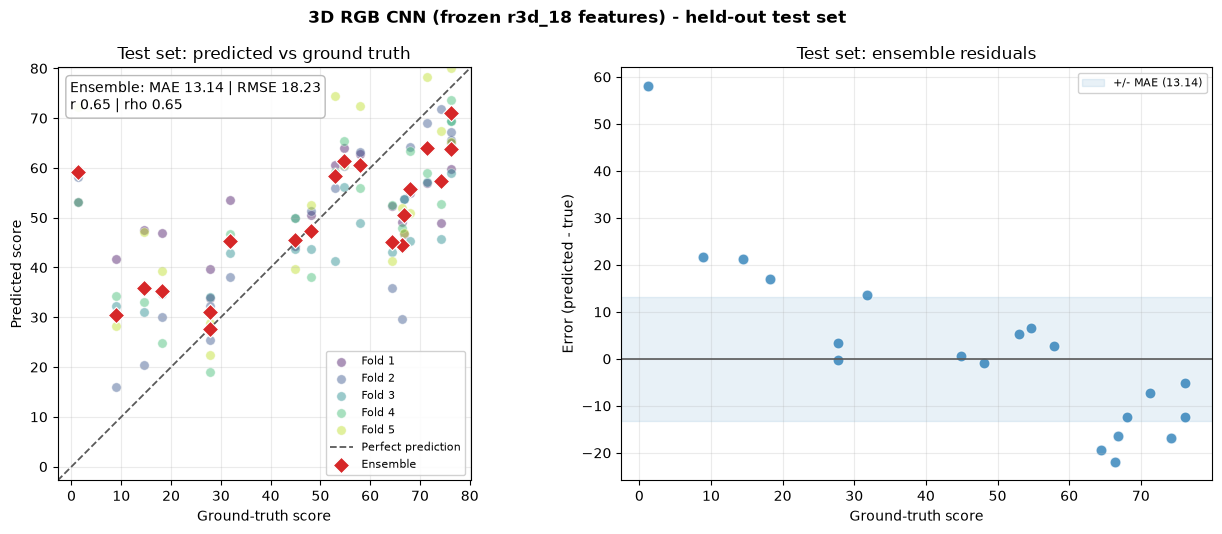

Saved plot -> C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\pred_vs_true_test_3dcnn.png

Test metrics per fold and ensemble:
   split    mae   rmse  pearson  spearman
  Fold 1 17.056 20.957    0.523     0.529
  Fold 2 11.193 17.626    0.669     0.739
  Fold 3 15.443 19.864    0.560     0.642
  Fold 4 12.741 16.936    0.704     0.707
  Fold 5 15.951 21.864    0.499     0.560
Ensemble 13.143 18.233    0.654     0.653


In [6]:
# --- 8. Visual diagnostics: predicted vs true test scores -----------------
# Rebuilds the test predictions from the cached features + saved fold heads,
# so this cell also works if you only rerun it (no need to rerun the CV cell).
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CACHE_PATH = CKPT_DIR / "r3d18_feature_cache_v1.npz"


class _PlotHead(nn.Module):
    """Same architecture/state_dict layout as FeatureHead in the CV cell."""

    def __init__(self, in_dim=512, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


@torch.no_grad()
def _load_and_predict(path, X):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    head = _PlotHead(X.shape[1])
    head.load_state_dict(ckpt["state_dict"])
    head.eval()
    X = (X - ckpt["mean"].numpy()) / ckpt["std"].numpy()
    return head(torch.from_numpy(np.ascontiguousarray(X))).numpy() * 100.0


def _metrics(pred, true):
    pred = np.asarray(pred, float).ravel()
    true = np.asarray(true, float).ravel()
    return {
        "mae": float(np.mean(np.abs(pred - true))),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "pearson": float(pearsonr(pred, true)[0]) if len(pred) > 1 else 0.0,
        "spearman": float(spearmanr(pred, true)[0]) if len(pred) > 1 else 0.0,
    }


# --- Data: held-out test clips, clean view only ---------------------------
with np.load(CACHE_PATH, allow_pickle=False) as z:
    CACHE = {str(k): v for k, v in zip(z["keys"], z["features"])}

splits = pd.read_csv(DATA_DIR / "splits.csv", dtype={"filename": str})
test_df = splits[splits["split"] == "test"].reset_index(drop=True)
test_names = test_df["filename"].astype(str)
y_true = test_df["target"].to_numpy(np.float64)
X_test = np.stack([CACHE[f"{n}|0"] for n in test_names])

head_paths = sorted(CKPT_DIR.glob("best_head_fold*.pth"),
                    key=lambda p: int(p.stem.replace("best_head_fold", "")))
assert head_paths, f"no head checkpoints found in {CKPT_DIR}"

fold_preds = np.stack([_load_and_predict(p, X_test) for p in head_paths])
y_pred = fold_preds.mean(0)
m = _metrics(y_pred, y_true)
fold_metrics = [_metrics(fold_preds[i], y_true) for i in range(len(head_paths))]

# --- Plot ----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(head_paths)))

# (a) predicted vs ground truth
ax = axes[0]
for i in range(len(head_paths)):
    ax.scatter(y_true, fold_preds[i], s=46, alpha=0.45, color=colors[i],
               edgecolor="white", linewidth=0.6, label=f"Fold {i + 1}")

lo = min(y_true.min(), y_pred.min()) - 4
hi = max(y_true.max(), y_pred.max()) + 4
ax.plot([lo, hi], [lo, hi], "--", color="0.35", lw=1.3,
        label="Perfect prediction")
ax.scatter(y_true, y_pred, s=70, color="tab:red", marker="D",
           edgecolor="white", linewidth=0.8, zorder=5, label="Ensemble")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel("Ground-truth score")
ax.set_ylabel("Predicted score")
ax.set_title("Test set: predicted vs ground truth")
ax.grid(alpha=0.25)
ax.text(0.03, 0.97,
        f"Ensemble: MAE {m['mae']:.2f} | RMSE {m['rmse']:.2f}\n"
        f"r {m['pearson']:.2f} | rho {m['spearman']:.2f}",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9,
                  edgecolor="0.7"))
ax.legend(loc="lower right", fontsize=8, framealpha=0.9)

# (b) residuals of the ensemble
ax = axes[1]
resid = y_pred - y_true
ax.axhline(0, color="0.35", lw=1.2)
ax.axhspan(-m["mae"], m["mae"], color="tab:blue", alpha=0.10,
           label=f"+/- MAE ({m['mae']:.2f})")
ax.scatter(y_true, resid, s=60, color="tab:blue", alpha=0.75,
           edgecolor="white", linewidth=0.7)
ax.set_xlabel("Ground-truth score")
ax.set_ylabel("Error (predicted - true)")
ax.set_title("Test set: ensemble residuals")
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

fig.suptitle("3D RGB CNN (frozen r3d_18 features) - held-out test set",
             fontweight="bold")
fig.tight_layout()
out_path = DATA_DIR / "pred_vs_true_test_3dcnn.png"
fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot -> {out_path}")

summary = pd.DataFrame({
    "split": [f"Fold {i + 1}" for i in range(len(head_paths))] + ["Ensemble"],
    **{k: [fm[k] for fm in fold_metrics] + [m[k]]
       for k in ("mae", "rmse", "pearson", "spearman")},
})
print("\nTest metrics per fold and ensemble:")
print(summary.round(3).to_string(index=False))

In [ ]:
# --- 9. Improving near-zero scores: end-of-clip features + fall refinement ---
# Diagnosis with the current full-clip model:
#   * clips scored < 10 are predicted around 43 on average (never below ~10)
#   * clips scored >= 90 are predicted around 54
# The cause is regression to the mean plus global average pooling over the whole
# clip, which dilutes a fall that happens in the last second.
#
# Fix:
#   1) append features from the LAST 8 and LAST 4 frames (where the fall occurs)
#   2) use a pow25 target transform so MSE cares proportionally more about lows
#   3) optionally train a fall head (target < 15) and pull the score down when
#      it fires. Set USE_FALL_REFINE=False to keep the plain regressor.
#
# The section is additive: the baseline cells above are untouched.
import os
import time
import multiprocessing

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models.video as models_video
import torchvision.transforms.functional as TF
import decord
from scipy.stats import pearsonr, spearmanr

# --- Config ---------------------------------------------------------------
END_WINDOWS = ("last8", "last4")
TARGET_TRANSFORM = "pow25"      # identity | sqrt | pow25
USE_FALL_REFINE = True
FALL_MODE = "gate"              # "blend" (soft) or "gate" (snap confident falls down)
FALL_TAU = 0.55                 # gate threshold on p(fall)
FALL_THRESHOLD = 10.0           # clips below this are "falls" for the auxiliary head
FALL_ALPHA = 0.9                # blend strength (blend mode only)
FALL_ANCHOR = 7.5               # score used when the fall head is confident
SEED = 42
K_FOLDS = 5
TRAIN_VIEWS = (0, 1, 2)         # clean + 2 augmented full-clip views
HEAD_EPOCHS = 250
HEAD_PATIENCE = 40
HEAD_BATCH = 64
HEAD_LR = 6e-3
HEAD_WD = 1e-3

torch.set_num_threads(max(1, multiprocessing.cpu_count() - 2))
device = torch.device("cpu")

DATA_DIR = DATA_DIR if "DATA_DIR" in globals() else os.path.abspath(".")
DATA_DIR = os.path.abspath(DATA_DIR)
CKPT_DIR = os.path.join(DATA_DIR, "checkpoints_3dcnn")
FULL_CACHE = os.path.join(CKPT_DIR, "r3d18_feature_cache_v1.npz")
WINDOW_CACHE = os.path.join(CKPT_DIR, "r3d18_window_cache_v1.npz")

splits = pd.read_csv(os.path.join(DATA_DIR, "splits.csv"), dtype={"filename": str})
train_val_df = splits[splits["split"] != "test"].reset_index(drop=True)
test_df = splits[splits["split"] == "test"].reset_index(drop=True)


def _fold_ids(targets, n=K_FOLDS, seed=SEED):
    bins = pd.qcut(pd.Series(targets).rank(method="first"), n, labels=False).to_numpy()
    ids = np.empty(len(targets), int)
    rng = np.random.default_rng(seed)
    for b in range(n):
        idx = np.flatnonzero(bins == b)
        rng.shuffle(idx)
        ids[idx] = np.arange(len(idx)) % n
    return ids


fold_ids = _fold_ids(train_val_df["target"])
Y_TV = train_val_df["target"].to_numpy(np.float64)
Y_TE = test_df["target"].to_numpy(np.float64)


# --- 9.1 Build / load the end-of-clip feature cache ------------------------
def _find_video(stem):
    for name in (f"{stem}.mp4", f"{stem.zfill(3)}.avi", f"{stem}.avi"):
        p = os.path.join(DATA_DIR, name)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(stem)


def _load_clip_frames(stem, num_frames=16, img_size=112):
    vr = decord.VideoReader(_find_video(stem))
    idx = np.linspace(0, len(vr) - 1, num_frames, dtype=int)
    frames = torch.from_numpy(vr.get_batch(idx).asnumpy())
    x = frames.permute(0, 3, 1, 2).float() / 255.0
    x = TF.resize(x, [img_size, img_size])
    return TF.normalize(x, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])


def build_window_cache():
    """Extract r3d_18 features for the last 8 / last 4 frames of every clip."""
    backbone = models_video.r3d_18(weights=models_video.R3D_18_Weights.DEFAULT)
    backbone.fc = nn.Identity()
    backbone.eval()

    names = pd.concat([train_val_df, test_df], ignore_index=True)["filename"].astype(str).tolist()
    slices = {"last8": slice(8, 16), "last4": slice(12, 16)}
    keys, blocks = [], []
    t0 = time.time()
    for window, sl in slices.items():
        rows = []
        for start in range(0, len(names), 4):
            chunk = names[start:start + 4]
            xb = torch.stack([_load_clip_frames(n)[sl] for n in chunk])
            xb = xb.permute(0, 2, 1, 3, 4).contiguous()
            with torch.no_grad():
                rows.append(backbone(xb).flatten(1).numpy().astype(np.float32))
        F = np.concatenate(rows, 0)
        keys.extend([f"{n}|{window}" for n in names])
        blocks.append(F)
        print(f"  {window}: {F.shape} | {time.time() - t0:.0f}s")
    np.savez_compressed(WINDOW_CACHE, keys=np.array(keys),
                        features=np.concatenate(blocks, 0))
    print(f"  saved {WINDOW_CACHE}")


def load_npz(path):
    with np.load(path, allow_pickle=False) as z:
        return {str(k): v for k, v in zip(z["keys"], z["features"])}


assert os.path.exists(FULL_CACHE), (
    f"Missing {FULL_CACHE}. Run the fast 3D CNN CV cell first.")
FULL = load_npz(FULL_CACHE)
if not os.path.exists(WINDOW_CACHE):
    print("Building end-of-clip feature cache (one-time, ~2 min)...")
    build_window_cache()
WIN = load_npz(WINDOW_CACHE)


# --- 9.2 Feature matrices --------------------------------------------------
def feature_row(stem, view):
    return np.concatenate([FULL[f"{stem}|{view}"]] +
                          [WIN[f"{stem}|{w}"] for w in END_WINDOWS])


X_tr = np.stack([feature_row(n, v)
                 for n in train_val_df["filename"].astype(str)
                 for v in TRAIN_VIEWS])
Y_tr = np.repeat(Y_TV, len(TRAIN_VIEWS))
REP = np.repeat(fold_ids, len(TRAIN_VIEWS))   # fold id of each repeated row

X_va_all = np.stack([feature_row(n, 0) for n in train_val_df["filename"].astype(str)])
X_te = np.stack([feature_row(n, 0) for n in test_df["filename"].astype(str)])
X_last8_tv = np.stack([WIN[f"{n}|last8"] for n in train_val_df["filename"].astype(str)])
X_last8_te = np.stack([WIN[f"{n}|last8"] for n in test_df["filename"].astype(str)])


class MLP(nn.Module):
    def __init__(self, d, out_dim=1, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(d, 64), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(64, out_dim))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def _fwd_transform(y):
    if TARGET_TRANSFORM == "sqrt":
        return np.sqrt(np.clip(y, 0, None))
    if TARGET_TRANSFORM == "pow25":
        return np.power(np.clip(y, 0, None) / 100.0, 0.25) * 100.0
    return y


def _inv_transform(z):
    if TARGET_TRANSFORM == "sqrt":
        return z ** 2
    if TARGET_TRANSFORM == "pow25":
        return np.power(np.clip(z, 0, None) / 100.0, 4.0) * 100.0
    return z


def train_regressor(Xtr, ytr, Xva, yva, seed):
    mu = Xtr.mean(0, keepdims=True)
    sd = Xtr.std(0, keepdims=True) + 1e-6
    Xt = torch.from_numpy(np.ascontiguousarray((Xtr - mu) / sd))
    Xv = torch.from_numpy(np.ascontiguousarray((Xva - mu) / sd))
    z = _fwd_transform(ytr)
    z_mean, z_std = z.mean(), z.std() + 1e-6
    zt = torch.from_numpy(((z - z_mean) / z_std).astype(np.float32))

    torch.manual_seed(seed)
    model = MLP(Xtr.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=10)
    best, best_state, bad = float("inf"), None, 0

    def predict(xb):
        with torch.no_grad():
            raw = model(xb).numpy() * z_std + z_mean
        return np.clip(_inv_transform(raw), 0.0, 100.0)

    for epoch in range(HEAD_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            opt.zero_grad(set_to_none=True)
            F.mse_loss(model(Xt[idx]), zt[idx]).backward()
            opt.step()
        model.eval()
        mae = float(np.mean(np.abs(predict(Xv) - yva)))
        sched.step(mae)
        if mae < best - 1e-4:
            best, bad = mae, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= HEAD_PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, (mu, sd, z_mean, z_std)


def train_fall_head(Xtr, ytr, seed, epochs=200):
    mu = Xtr.mean(0, keepdims=True)
    sd = Xtr.std(0, keepdims=True) + 1e-6
    Xt = torch.from_numpy(np.ascontiguousarray((Xtr - mu) / sd))
    yt = torch.from_numpy(ytr.astype(np.float32))
    pos = float(ytr.sum())
    pw = torch.tensor((len(ytr) - pos) / max(pos, 1.0))

    torch.manual_seed(seed)
    model = MLP(Xtr.shape[1], 1, dropout=0.3)
    opt = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WD)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            opt.zero_grad(set_to_none=True)
            F.binary_cross_entropy_with_logits(model(Xt[idx]), yt[idx],
                                               pos_weight=pw).backward()
            opt.step()
    model.eval()
    return model, (mu, sd)


def predict_reg(model, scaler, X):
    mu, sd, z_mean, z_std = scaler
    with torch.no_grad():
        raw = model(torch.from_numpy(np.ascontiguousarray((X - mu) / sd))).numpy()
    return np.clip(_inv_transform(raw * z_std + z_mean), 0.0, 100.0)


def predict_fall(model, scaler, X):
    mu, sd = scaler
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(
            np.ascontiguousarray((X - mu) / sd)))).numpy()


def reg_metrics(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return {
        "mae": float(np.mean(np.abs(pred - true))),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "pearson": float(pearsonr(pred, true)[0]) if np.std(pred) > 0 else float("nan"),
        "spearman": float(spearmanr(pred, true)[0]) if np.std(pred) > 0 else float("nan"),
    }


# --- 9.3 5-fold CV: regressor + optional fall head -------------------------
reg_oof = np.full(len(train_val_df), np.nan)
p_fall_oof = np.full(len(train_val_df), np.nan)
reg_test_folds, p_fall_test_folds = [], []
y_fall = (Y_TV < FALL_THRESHOLD).astype(int)
t0 = time.time()

for fold in range(K_FOLDS):
    tr = REP != fold
    va = fold_ids == fold
    fit = fold_ids != fold

    model, scaler = train_regressor(X_tr[tr], Y_tr[tr], X_va_all[va], Y_TV[va], SEED + fold)
    reg_oof[va] = predict_reg(model, scaler, X_va_all[va])
    reg_test_folds.append(predict_reg(model, scaler, X_te))
    torch.save({"state_dict": model.state_dict(), "mean": scaler[0], "std": scaler[1],
                "z_mean": scaler[2], "z_std": scaler[3], "transform": TARGET_TRANSFORM,
                "windows": list(END_WINDOWS), "in_dim": X_tr.shape[1]},
               os.path.join(CKPT_DIR, f"end_head_fold{fold}.pth"))

    if USE_FALL_REFINE:
        fall_model, fall_scaler = train_fall_head(X_last8_tv[fit], y_fall[fit], SEED + fold)
        p_fall_oof[va] = predict_fall(fall_model, fall_scaler, X_last8_tv[va])
        p_fall_test_folds.append(predict_fall(fall_model, fall_scaler, X_last8_te))
        torch.save({"state_dict": fall_model.state_dict(),
                    "mean": fall_scaler[0], "std": fall_scaler[1],
                    "threshold": FALL_THRESHOLD},
                   os.path.join(CKPT_DIR, f"fall_head_fold{fold}.pth"))

    print(f"fold {fold}: reg MAE {np.mean(np.abs(reg_oof[va] - Y_TV[va])):5.2f} | "
          f"y<10 pred {reg_oof[va][Y_TV[va] < 10].mean() if (Y_TV[va] < 10).any() else float('nan'):5.1f}")

reg_test = np.mean(reg_test_folds, 0)
if USE_FALL_REFINE:
    p_fall_test = np.mean(p_fall_test_folds, 0)
    if FALL_MODE == "gate":
        pred_oof = np.where(p_fall_oof >= FALL_TAU, FALL_ANCHOR, reg_oof)
        pred_test = np.where(p_fall_test >= FALL_TAU, FALL_ANCHOR, reg_test)
    else:
        pred_oof = np.clip((1 - FALL_ALPHA * p_fall_oof) * reg_oof
                           + (FALL_ALPHA * p_fall_oof) * FALL_ANCHOR, 0, 100)
        pred_test = np.clip((1 - FALL_ALPHA * p_fall_test) * reg_test
                            + (FALL_ALPHA * p_fall_test) * FALL_ANCHOR, 0, 100)
else:
    pred_oof, pred_test = reg_oof, reg_test

# --- Baseline (full-clip sigmoid heads from cell 5) for comparison ---------
class BaselineHead(nn.Module):
    """Matches the state_dict layout saved by the fast CV cell."""
    def __init__(self, in_dim=512, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(in_dim, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 1), nn.Sigmoid())

    def forward(self, x):
        return self.net(x).squeeze(-1)


def load_baseline_head(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    head = BaselineHead(ckpt["state_dict"]["net.1.weight"].shape[1], dropout=0.5)
    head.load_state_dict(ckpt["state_dict"])
    head.eval()
    return head, ckpt["mean"].numpy(), ckpt["std"].numpy()


X_full_va = np.stack([FULL[f"{n}|0"] for n in train_val_df["filename"].astype(str)])
X_full_te = np.stack([FULL[f"{n}|0"] for n in test_df["filename"].astype(str)])
base_oof = np.full(len(train_val_df), np.nan)
base_test_folds = []
for fold in range(K_FOLDS):
    path = os.path.join(CKPT_DIR, f"best_head_fold{fold}.pth")
    if not os.path.exists(path):
        base_oof = None
        break
    head, mean, std = load_baseline_head(path)
    va = fold_ids == fold
    with torch.no_grad():
        base_oof[va] = head(torch.from_numpy(
            np.ascontiguousarray((X_full_va[va] - mean) / std))).numpy() * 100.0
        base_test_folds.append(head(torch.from_numpy(
            np.ascontiguousarray((X_full_te - mean) / std))).numpy() * 100.0)
base_test = np.mean(base_test_folds, 0) if base_test_folds else None

# --- Report ----------------------------------------------------------------
def low_stats(pred, true, thr):
    m = true < thr
    return f"{(pred[m].mean() if m.any() else float('nan')):5.1f}"


rows = []
if base_oof is not None:
    mb, mt = reg_metrics(base_oof, Y_TV), reg_metrics(base_test, Y_TE)
    rows.append({"model": "baseline full-clip", "oof_mae": mb["mae"], "oof_r": mb["pearson"],
                 "test_mae": mt["mae"], "test_r": mt["pearson"],
                 "oof_pred_y<10": low_stats(base_oof, Y_TV, 10),
                 "oof_pred_y<20": low_stats(base_oof, Y_TV, 20)})
mr, mtr = reg_metrics(reg_oof, Y_TV), reg_metrics(reg_test, Y_TE)
rows.append({"model": "end-of-clip + pow25", "oof_mae": mr["mae"], "oof_r": mr["pearson"],
             "test_mae": mtr["mae"], "test_r": mtr["pearson"],
             "oof_pred_y<10": low_stats(reg_oof, Y_TV, 10),
             "oof_pred_y<20": low_stats(reg_oof, Y_TV, 20)})
if USE_FALL_REFINE:
    mp, mtp = reg_metrics(pred_oof, Y_TV), reg_metrics(pred_test, Y_TE)
    rows.append({"model": "end + fall refine", "oof_mae": mp["mae"], "oof_r": mp["pearson"],
                 "test_mae": mtp["mae"], "test_r": mtp["pearson"],
                 "oof_pred_y<10": low_stats(pred_oof, Y_TV, 10),
                 "oof_pred_y<20": low_stats(pred_oof, Y_TV, 20)})

print(f"\nNear-zero improvement (CV took {time.time() - t0:.1f}s):")
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nReference: the y<10 group is", int((Y_TV < 10).sum()),
      "clips with true mean", round(float(Y_TV[Y_TV < 10].mean()), 2))

# --- Plot ------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
ax = axes[0]
if base_oof is not None:
    ax.scatter(Y_TV, base_oof, s=36, alpha=0.45, color="0.65", label="baseline full-clip")
ax.scatter(Y_TV, pred_oof, s=44, alpha=0.75, color="tab:blue",
           label="end + fall refine" if USE_FALL_REFINE else "end-of-clip")
low = Y_TV < 20
ax.scatter(Y_TV[low], pred_oof[low], s=70, facecolors="none", edgecolors="tab:red",
           linewidths=1.5, label="true score < 20")
ax.plot([0, 100], [0, 100], "k--", lw=1)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("true score"); ax.set_ylabel("out-of-fold prediction")
ax.set_title("OOF: near-zero clips can now be pulled down")
ax.legend(fontsize=8); ax.grid(alpha=0.25)

# MAE by true-score bin, baseline vs full pipeline
edges = np.arange(0, 101, 10)
centers = edges[:-1] + 5
base_bins, new_bins = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (Y_TV >= lo) & (Y_TV < hi)
    base_bins.append(np.mean(np.abs(base_oof[m] - Y_TV[m])) if base_oof is not None and m.any() else np.nan)
    new_bins.append(np.mean(np.abs(pred_oof[m] - Y_TV[m])) if m.any() else np.nan)
ax = axes[1]
ax.bar(centers - 2.2, base_bins, width=4.2, label="baseline", color="0.7")
ax.bar(centers + 2.2, new_bins, width=4.2, label="improved", color="tab:blue")
ax.set_xlabel("true score bin"); ax.set_ylabel("MAE (points)")
ax.set_title("Error by score bin")
ax.legend(fontsize=8); ax.grid(alpha=0.25, axis="y")

fig.suptitle("3D RGB CNN: improving near-zero predictions", fontweight="bold")
fig.tight_layout()
out = os.path.join(DATA_DIR, "low_score_improvement.png")
fig.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot -> {out}")

print("\nTest clips with true score < 20:")
m = Y_TE < 20
for name, y, b, r in zip(test_df["filename"].astype(str)[m], Y_TE[m],
                         (base_test[m] if base_test is not None else np.full(m.sum(), np.nan)),
                         (pred_test[m])):
    print(f"  {name:12s} true {y:5.1f} | baseline {b:5.1f} | improved {r:5.1f}")


## YOLO pose pipeline (cached keypoints + augmented training)

Keypoints are extracted with YOLOv8-Pose **once** per clip and cached as normalised `(N_frames, 17, 3)` arrays (`x`, `y`, `confidence`). The dataset cell below adds clip-level augmentation **only for the training split**: horizontal flip with L/R joint swap, temporal crop/resample, speed jitter, small scale/translation jitter, keypoint noise, and joint dropout. Validation and test clips remain unaugmented.


In [ ]:
# --- 1. Pose cache: extract once, reuse for every epoch ------------------
# Frames are decoded full-length, every detected person's keypoints are
# normalized to [0, 1] image coordinates, and the keypoint confidence is kept
# as a third channel so missing joints are distinguishable from (0, 0).
# Cache layout: pose_cache/<filename>.npz  ->  pose (N_frames, 17, 3), fps, width, height
import time
import decord
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from ultralytics import YOLO

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CACHE_DIR = DATA_DIR / "pose_cache"
CACHE_DIR.mkdir(exist_ok=True)

POSE_WEIGHTS = "yolov8n-pose.pt"
POSE_CONF = 0.25
POSE_IMGSZ = 640        # detection resolution; keypoints are normalized afterwards
FRAME_BATCH = 32        # frames per YOLO call
MIN_FRAMES = 16         # clips shorter than this are unusable, skip them
CACHE_VERSION = 2       # bump whenever POSE_* settings change
DEVICE = 0 if torch.cuda.is_available() else "cpu"

pose_model = YOLO(POSE_WEIGHTS)


def find_video(stem):
    """Resolve a label stem to its .mp4/.avi file (numeric labels are zero-padded)."""
    stem = str(stem)
    for name in (f"{stem}.mp4", f"{stem.zfill(3)}.avi", f"{stem}.avi"):
        candidate = DATA_DIR / name
        if candidate.is_file():
            return candidate
    return None


def cache_is_current(out_path, video_path):
    """True only if the cache was built with the current settings and is newer than the video."""
    if not out_path.exists() or out_path.stat().st_mtime < video_path.stat().st_mtime:
        return False
    try:
        with np.load(out_path) as cached:
            return (int(cached["version"]) == CACHE_VERSION
                    and int(cached["imgsz"]) == POSE_IMGSZ
                    and float(cached["conf"]) == POSE_CONF
                    and str(cached["weights"]) == POSE_WEIGHTS)
    except Exception:
        return False


def extract_pose(video_path):
    """Return (N, 17, 3): normalized x, y, keypoint confidence for every frame."""
    vr = decord.VideoReader(str(video_path))
    n = len(vr)
    height, width = vr[0].shape[:2]
    pose = np.zeros((n, 17, 3), dtype=np.float32)

    for start in range(0, n, FRAME_BATCH):
        frames = vr.get_batch(np.arange(start, min(start + FRAME_BATCH, n))).asnumpy()
        results = pose_model(list(frames), verbose=False, conf=POSE_CONF,
                             imgsz=POSE_IMGSZ, device=DEVICE)

        for offset, result in enumerate(results):
            keypoints = result.keypoints
            if keypoints is None or keypoints.xy is None or len(keypoints.xy) == 0:
                continue

            # Pick the largest detected person: the main subject, not a spectator.
            if result.boxes is not None and len(result.boxes) > 0:
                wh = result.boxes.xywh[:, 2:4]
                person = int(torch.argmax(wh[:, 0] * wh[:, 1]).item())
            else:
                person = 0

            xy = keypoints.xy[person].cpu().numpy()
            conf = (keypoints.conf[person].cpu().numpy()
                    if keypoints.conf is not None else np.ones(17, dtype=np.float32))

            frame_idx = start + offset
            pose[frame_idx, :, 0] = np.clip(xy[:, 0] / width, 0.0, 1.0)
            pose[frame_idx, :, 1] = np.clip(xy[:, 1] / height, 0.0, 1.0)
            pose[frame_idx, :, 2] = conf

    return pose


def build_pose_cache(csv_file="filtered_labels.csv", force=False):
    """Extract every clip listed in csv_file once. Resumable; stale caches are rebuilt."""
    csv_path = Path(csv_file)
    if not csv_path.is_absolute():
        csv_path = DATA_DIR / csv_path
    df = pd.read_csv(csv_path, sep=",")

    jobs, skipped = [], []
    for stem in df["filename"].astype(str):
        video_path = find_video(stem)
        out_path = CACHE_DIR / f"{stem}.npz"
        if video_path is None:
            skipped.append((stem, None, "video missing"))
            continue
        try:
            n_frames = len(decord.VideoReader(str(video_path)))
        except Exception as exc:
            skipped.append((stem, None, f"decode error: {exc}"))
            continue
        if n_frames < MIN_FRAMES:
            skipped.append((stem, n_frames, f"too short ({n_frames} frames)"))
            continue
        if not force and cache_is_current(out_path, video_path):
            continue
        jobs.append((stem, video_path, n_frames))

    print(f"cache: {len(jobs)} to extract, "
          f"{len(df) - len(jobs) - len(skipped)} up to date, {len(skipped)} skipped")
    if skipped:
        for stem, _, reason in skipped:
            print(f"  [SKIP] {stem}: {reason}")

    t0 = time.time()
    log = []
    for i, (stem, video_path, n_frames) in enumerate(jobs, 1):
        clip_start = time.time()
        try:
            pose = extract_pose(video_path)
            vr = decord.VideoReader(str(video_path))
            height, width = vr[0].shape[:2]
            np.savez_compressed(
                CACHE_DIR / f"{stem}.npz",
                pose=pose,
                fps=np.float32(vr.get_avg_fps()),
                width=width,
                height=height,
                version=CACHE_VERSION,
                imgsz=POSE_IMGSZ,
                conf=POSE_CONF,
                weights=POSE_WEIGHTS,
            )
            detected = int((pose[:, :, 2] > 0.1).any(axis=1).sum())
            log.append({"filename": stem, "frames": len(pose),
                        "detected_frames": detected, "status": "ok"})
        except Exception as exc:
            log.append({"filename": stem, "frames": n_frames,
                        "detected_frames": 0, "status": f"error: {exc}"})

        if i % 10 == 0 or i == len(jobs):
            elapsed = time.time() - t0
            per_clip = elapsed / i
            print(f"  [{i}/{len(jobs)}] {stem} | {per_clip:.1f}s/clip, "
                  f"ETA {(len(jobs) - i) * per_clip / 60:.1f} min")

    for stem, n_frames, reason in skipped:
        log.append({"filename": stem, "frames": n_frames,
                    "detected_frames": 0, "status": reason})
    if log:
        pd.DataFrame(log).to_csv(CACHE_DIR / "build_log.csv", sep=",", index=False)
    print(f"done in {(time.time() - t0) / 60:.1f} min; "
          f"{len(list(CACHE_DIR.glob('*.npz')))} cache files in {CACHE_DIR}")


build_pose_cache()   # pass force=True after changing POSE_* settings


In [ ]:
# --- 2. Fixed-length pose dataset + augmented training samples ------------
# Reuses the shared, already-built split table (splits.csv). Do NOT regenerate
# it here: the RGB pipeline uses the same file, and re-splitting would silently
# invalidate those train/val/test assignments.
#
# Every clip comes from pose_cache/<filename>.npz as (N_frames, 17, 3):
#   x, y  -> image coordinates normalised to [0, 1]
#   conf  -> YOLO keypoint confidence (0 = joint missing)
#
# Training split is wrapped in PoseAugmenter; val/test stay clean.
import random

import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader, Dataset

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CACHE_DIR = DATA_DIR / "pose_cache"
SPLITS_CSV = DATA_DIR / "splits.csv"

NUM_FRAMES = 64          # every clip becomes (64, 17, 3)
SEED = 42
BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# COCO-17 left/right joint pairs, used by the mirror augmentation
FLIP_INDEX = np.array([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15],
                      dtype=np.int64)


class PoseAugmenter:
    """Clip-level augmentation for cached skeletons of shape (T, 17, 3).

    All augmentations are applied consistently across the whole clip so the
    motion stays coherent. Geometry is kept in normalised [0, 1] coordinates.
    """

    def __init__(
        self,
        p_flip=0.5,
        p_temporal=0.5,
        p_speed=0.4,
        p_scale=0.5,
        p_noise=0.5,
        p_joint_drop=0.3,
        noise_std=0.006,
        scale_range=(0.90, 1.10),
        shift=0.02,
        joint_drop_prob=0.12,
        min_keep=0.60,
    ):
        self.p_flip = p_flip
        self.p_temporal = p_temporal
        self.p_speed = p_speed
        self.p_scale = p_scale
        self.p_noise = p_noise
        self.p_joint_drop = p_joint_drop
        self.noise_std = noise_std
        self.scale_range = scale_range
        self.shift = shift
        self.joint_drop_prob = joint_drop_prob
        self.min_keep = min_keep

    @staticmethod
    def _time_resample(pose, out_len):
        n = len(pose)
        if n == out_len:
            return pose.astype(np.float32, copy=False)
        src = np.linspace(0, n - 1, out_len)
        lo = np.floor(src).astype(int)
        hi = np.minimum(lo + 1, n - 1)
        w = (src - lo)[:, None, None].astype(np.float32)
        return (pose[lo] * (1.0 - w) + pose[hi] * w).astype(np.float32)

    def _temporal_crop(self, pose):
        """Keep a random contiguous 60-100 % window, resampled to full length."""
        n = len(pose)
        if n < 4:
            return pose
        keep = random.uniform(self.min_keep, 1.0)
        start = random.uniform(0.0, 1.0 - keep)
        lo = int(round(start * n))
        hi = min(n, max(lo + 2, int(round((start + keep) * n))))
        return self._time_resample(pose[lo:hi], n)

    def _speed_jitter(self, pose):
        """Non-uniform time resampling = slightly faster / slower performance."""
        n = len(pose)
        if n < 4:
            return pose
        speed = random.uniform(0.75, 1.25)
        src = (np.linspace(0.0, 1.0, n) ** speed) * (n - 1)
        lo = np.floor(src).astype(int)
        hi = np.minimum(lo + 1, n - 1)
        w = (src - lo)[:, None, None].astype(np.float32)
        return (pose[lo] * (1.0 - w) + pose[hi] * w).astype(np.float32)

    def _horizontal_flip(self, pose):
        """Mirror x and swap left/right joints."""
        pose = pose.copy()
        pose[..., 0] = 1.0 - pose[..., 0]
        return pose[:, FLIP_INDEX, :]

    def _spatial_jitter(self, pose):
        """Small scale / translation jitter around the image centre."""
        scale = random.uniform(*self.scale_range)
        tx = random.uniform(-self.shift, self.shift)
        ty = random.uniform(-self.shift, self.shift)
        pose = pose.copy()
        pose[..., 0] = np.clip((pose[..., 0] - 0.5) * scale + 0.5 + tx, 0.0, 1.0)
        pose[..., 1] = np.clip((pose[..., 1] - 0.5) * scale + 0.5 + ty, 0.0, 1.0)
        return pose

    def _add_noise(self, pose):
        """Detector-like jitter, only on joints that were actually detected."""
        mask = pose[..., 2:3] > 0.1
        noise = np.random.randn(*pose[..., :2].shape).astype(np.float32)
        pose = pose.copy()
        pose[..., :2] = np.clip(pose[..., :2] + noise * self.noise_std * mask,
                                0.0, 1.0)
        return pose

    def _joint_dropout(self, pose):
        """Simulate missing detections for a random subset of joints (whole clip)."""
        drop = np.random.rand(pose.shape[1]) < self.joint_drop_prob
        if drop.any():
            pose = pose.copy()
            pose[:, drop, :2] = 0.0
            pose[:, drop, 2] = 0.0
        return pose

    def __call__(self, pose):
        pose = np.asarray(pose, dtype=np.float32).copy()
        if random.random() < self.p_temporal:
            pose = self._temporal_crop(pose)
        if random.random() < self.p_speed:
            pose = self._speed_jitter(pose)
        if random.random() < self.p_flip:
            pose = self._horizontal_flip(pose)
        if random.random() < self.p_scale:
            pose = self._spatial_jitter(pose)
        if random.random() < self.p_noise:
            pose = self._add_noise(pose)
        if random.random() < self.p_joint_drop:
            pose = self._joint_dropout(pose)
        return np.ascontiguousarray(pose, dtype=np.float32)


class PoseSequenceDataset(Dataset):
    """Fixed-length skeleton sequences from the pose cache.

    `data` is a DataFrame with at least `filename` and `target` columns.
    Set `augment=True` for training splits; val/test should stay clean.
    """

    def __init__(self, data, cache_dir=CACHE_DIR, num_frames=NUM_FRAMES,
                 augment=False, augmenter=None):
        self.data = data.reset_index(drop=True).copy()
        self.cache_dir = Path(cache_dir)
        self.num_frames = num_frames
        self.augment = augment
        self.augmenter = augmenter if augmenter is not None else PoseAugmenter()

        missing = [f for f in self.data["filename"].astype(str)
                   if not (self.cache_dir / f"{f}.npz").exists()]
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} clip(s) have no pose cache: {missing[:5]}. "
                f"Run the cache cell first."
            )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        stem = str(row["filename"])
        with np.load(self.cache_dir / f"{stem}.npz") as cached:
            pose = cached["pose"]                       # (N_frames, 17, 3)

        if self.augment:
            pose = self.augmenter(pose)

        indices = np.linspace(0, len(pose) - 1, self.num_frames, dtype=int)
        sequence = torch.from_numpy(
            np.ascontiguousarray(pose[indices], dtype=np.float32))
        target = torch.tensor(float(row["target"]), dtype=torch.float32)
        return sequence, target


class CachedPoseDataset(PoseSequenceDataset):
    """PoseSequenceDataset restricted to one split of splits.csv."""

    def __init__(self, split, splits_csv=SPLITS_CSV, num_frames=NUM_FRAMES,
                 augment=False, augmenter=None, cache_dir=CACHE_DIR):
        splits = pd.read_csv(splits_csv, dtype={"filename": str})
        data = splits[splits["split"] == split]
        if not len(data):
            raise ValueError(f"split '{split}' is empty in {splits_csv}")
        super().__init__(data, cache_dir=cache_dir, num_frames=num_frames,
                         augment=augment, augmenter=augmenter)


splits = pd.read_csv(SPLITS_CSV, dtype={"filename": str})
train_augmenter = PoseAugmenter()

train_dataset = CachedPoseDataset("train")
train_dataset_aug = CachedPoseDataset("train", augment=True,
                                      augmenter=train_augmenter)
val_dataset = CachedPoseDataset("val")
test_dataset = CachedPoseDataset("test")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0)

# --- Sanity checks --------------------------------------------------------
train_names = set(train_dataset.data["filename"].astype(str))
val_names = set(val_dataset.data["filename"].astype(str))
test_names = set(test_dataset.data["filename"].astype(str))
assert not (train_names & val_names or train_names & test_names
            or val_names & test_names), "split leakage"
assert len(train_names) + len(val_names) + len(test_names) == len(splits), \
    "rows lost in split"

for name, dataset in (("train", train_dataset), ("val", val_dataset),
                      ("test", test_dataset)):
    t = dataset.data["target"]
    print(f"{name:5s}: {len(dataset):3d} clips | target mean {t.mean():5.1f} "
          f"std {t.std():5.1f} range {t.min()}-{t.max()}")

xb, yb = next(iter(train_loader))
xa, _ = next(iter(train_loader_aug))
print(f"\nbatch: x {tuple(xb.shape)} (batch, time, joints, x/y/confidence), "
      f"y {tuple(yb.shape)}")
print(f"value ranges: x/y [{xb[:, :, :, :2].min():.3f}, "
      f"{xb[:, :, :, :2].max():.3f}], "
      f"confidence [{xb[:, :, :, 2].min():.3f}, {xb[:, :, :, 2].max():.3f}]")
print(f"targets: {yb[:8].tolist()}")

# The augmented batch should differ from the clean one but keep the same shape.
assert xa.shape == xb.shape
print(f"augmentation: |clean - augmented| mean "
      f"{(xa - xb).abs().mean():.4f} | "
      f"max {(xa - xb).abs().max():.3f}")
print(f"augmented x/y range: [{xa[:, :, :, :2].min():.3f}, "
      f"{xa[:, :, :, :2].max():.3f}]")


In [ ]:
# --- 3. Baseline model: bidirectional GRU over cached poses -------------
# Input:  (batch, 64 frames, 17 joints, x/y/confidence)
# Output: one score in [0, 100]. Targets are scaled by 100 for training only.
# Training uses the augmented pose split; validation/test stay clean.
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

SEED = 42
MAX_EPOCHS = 150
PATIENCE = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
TARGET_SCALE = 100.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

# COCO-17 left/right joint pairs, used for horizontal-flip augmentation
FLIP_INDEX = torch.tensor([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15])


def mask_missing_joints(x):
    """Zero x/y where keypoint confidence is negligible (confidence stays as a feature)."""
    x = x.clone()
    x[..., :2] = x[..., :2] * (x[..., 2:3] > 0.1)
    return x


def flip_poses(x):
    """Mirror x and swap left/right joints. x: (batch, time, 17, 3)."""
    x = x.clone()
    x[..., 0] = 1.0 - x[..., 0]
    return x[:, :, FLIP_INDEX.to(x.device), :]


class PoseGRUBaseline(nn.Module):
    def __init__(self, num_joints=17, in_channels=3, hidden=96, dropout=0.2):
        super().__init__()
        in_dim = num_joints * in_channels
        self.norm = nn.LayerNorm(in_dim)
        self.gru = nn.GRU(in_dim, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Linear(hidden * 4, 64),   # mean + max pooling over time
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        batch, time, joints, channels = x.shape
        x = self.norm(x.reshape(batch, time, joints * channels))
        out, _ = self.gru(x)
        pooled = torch.cat([out.mean(dim=1), out.amax(dim=1)], dim=1)
        return self.head(pooled).squeeze(-1)


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    losses, predictions, targets = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        # Flip / temporal / noise augmentation now happens in the dataset's
        # PoseAugmenter, so the training loop only needs to mask missing joints.
        x = mask_missing_joints(x)

        with torch.set_grad_enabled(training):
            output = model(x)
            loss = criterion(output, y / TARGET_SCALE)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()

        losses.append(loss.item())
        predictions.append((output.detach() * TARGET_SCALE).cpu())
        targets.append(y.detach().cpu())

    predictions = torch.cat(predictions).numpy()
    targets = torch.cat(targets).numpy()
    mae = float(np.mean(np.abs(predictions - targets)))
    return float(np.mean(losses)), mae, predictions, targets


def regression_metrics(y_true, y_pred):
    if np.std(y_pred) == 0 or np.std(y_true) == 0:
        pearson = spearman = float("nan")
    else:
        pearson = float(pearsonr(y_true, y_pred)[0])
        spearman = float(spearmanr(y_true, y_pred)[0])
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": pearson,
        "spearman": spearman,
    }


def evaluate(model, loader):
    criterion = nn.SmoothL1Loss(beta=0.05)
    _, _, predictions, targets = run_epoch(model, loader, criterion)
    return regression_metrics(targets, predictions), predictions, targets


model = PoseGRUBaseline().to(DEVICE)
criterion = nn.SmoothL1Loss(beta=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)
print(f"device: {DEVICE} | parameters: {sum(p.numel() for p in model.parameters()):,}")

best_val_mae, best_epoch, wait = float("inf"), 0, 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_mae, _, _ = run_epoch(model, train_loader_aug, criterion, optimizer)
    val_loss, val_mae, _, _ = run_epoch(model, val_loader, criterion)
    scheduler.step()

    history.append({
        "epoch": epoch, "train_loss": train_loss, "train_mae": train_mae,
        "val_loss": val_loss, "val_mae": val_mae,
        "lr": optimizer.param_groups[0]["lr"],
    })

    if val_mae < best_val_mae - 1e-3:
        best_val_mae, best_epoch, wait = val_mae, epoch, 0
        torch.save(model.state_dict(), CKPT_DIR / "baseline_gru.pt")
    else:
        wait += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | train MAE {train_mae:5.2f} | val MAE {val_mae:5.2f} "
              f"| lr {optimizer.param_groups[0]['lr']:.1e}")

    if wait >= PATIENCE:
        print(f"early stopping at epoch {epoch} (best val MAE {best_val_mae:.2f} @ epoch {best_epoch})")
        break

pd.DataFrame(history).to_csv(DATA_DIR / "baseline_history.csv", sep=",", index=False)
model.load_state_dict(torch.load(CKPT_DIR / "baseline_gru.pt", map_location=DEVICE))

# --- Report model vs the predict-the-train-mean baseline ----------------
train_mean = float(train_dataset.data["target"].mean())
print(f"\nbest checkpoint: epoch {best_epoch}, val MAE {best_val_mae:.2f}")
print(f"predict-mean baseline (train mean {train_mean:.1f}):")
for name, dataset, loader in (("train", train_dataset, train_loader),
                               ("val", val_dataset, val_loader),
                               ("test", test_dataset, test_loader)):
    y = dataset.data["target"].to_numpy(dtype=float)
    mean_mae = float(np.mean(np.abs(y - train_mean)))
    metrics, _, _ = evaluate(model, loader)
    print(f"  {name:5s} | mean-baseline MAE {mean_mae:5.2f} | model MAE {metrics['mae']:5.2f} "
          f"RMSE {metrics['rmse']:5.2f} | Pearson {metrics['pearson']:+.2f} "
          f"| Spearman {metrics['spearman']:+.2f}")


In [ ]:
# --- 4. Baseline diagnostics: curves + test predictions ------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

history = pd.read_csv(DATA_DIR / "baseline_history.csv", sep=",")
test_metrics, test_pred, test_true = evaluate(model, test_loader)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_mae"], label="train")
axes[0].plot(history["epoch"], history["val_mae"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MAE (points)")
axes[0].set_title("MAE")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_loss"], label="train")
axes[1].plot(history["epoch"], history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("SmoothL1 (scaled target)")
axes[1].set_title("Loss")
axes[1].legend()
fig.tight_layout()
fig.savefig(DATA_DIR / "baseline_curves.png", dpi=150)

fig2, ax = plt.subplots(figsize=(5, 5))
ax.scatter(test_true, test_pred, alpha=0.75)
ax.plot([0, 100], [0, 100], "k--", linewidth=1)
ax.set_xlabel("true score")
ax.set_ylabel("predicted score")
ax.set_title(f"Test set (n={len(test_true)}) — MAE {test_metrics['mae']:.1f}, "
             f"Spearman {test_metrics['spearman']:+.2f}")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
fig2.tight_layout()
fig2.savefig(DATA_DIR / "baseline_test_predictions.png", dpi=150)
plt.show()
print(test_metrics)


In [ ]:
# --- 5. Pose ST-GCN-lite + CORAL ordinal head, 5-fold CV + ensemble ------
# Graph convolutions over the COCO-17 skeleton, per-frame pose normalisation,
# attention pooling, and an ordinal head over 10 score bins. CV runs on
# train+val (183 clips); the 20-clip test set is never used for training.
# Fold fitting uses the augmented pose split; early-stop/val/test are clean.
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import pearsonr, spearmanr
from torch.utils.data import ConcatDataset, DataLoader, Subset

assert all(name in globals() for name in ("train_dataset", "val_dataset", "test_dataset")), \
    "Run the dataset cell (2) first."

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

SEED = 42
NUM_FOLDS = 5
NUM_BINS = 10
STGCN_EPOCHS = 120
STGCN_PATIENCE = 15
STGCN_BATCH_SIZE = 32
STGCN_LR = 1e-3
STGCN_WD = 5e-4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FLIP_INDEX = torch.tensor([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15])

COCO_EDGES = [
    (0, 1), (0, 2), (1, 3), (2, 4),
    (0, 5), (0, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 6), (5, 11), (6, 12),
    (11, 13), (13, 15), (12, 14), (14, 16),
    (11, 12),
]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def flip_poses(x):
    """Mirror x and swap left/right joints. x: (batch, time, 17, 3)."""
    x = x.clone()
    x[..., 0] = 1.0 - x[..., 0]
    return x[:, :, FLIP_INDEX.to(x.device), :]


def build_adjacency(num_joints=17, edges=COCO_EDGES):
    """Symmetric skeleton adjacency with self-loops, D^-1/2 (A + I) D^-1/2."""
    a = np.eye(num_joints, dtype=np.float32)
    for i, j in edges:
        a[i, j] = a[j, i] = 1.0
    d_inv_sqrt = np.diag(1.0 / np.sqrt(a.sum(axis=1)))
    return d_inv_sqrt @ a @ d_inv_sqrt


def pose_features(x):
    """Per-frame translation/scale normalisation + confidence + velocities."""
    conf = x[..., 2:3]
    valid = (conf > 0.1).float()
    xy = x[..., :2] * valid
    count = valid.sum(dim=2, keepdim=True).clamp(min=1.0)
    mean = (xy * valid).sum(dim=2, keepdim=True) / count
    dev = (xy - mean) * valid
    std = ((dev ** 2).sum(dim=2, keepdim=True) / count).sqrt().clamp(min=1e-3)
    xy_n = dev / std
    velocity = torch.zeros_like(xy_n)
    velocity[:, 1:] = xy_n[:, 1:] - xy_n[:, :-1]
    return torch.cat([xy_n, conf, velocity], dim=-1)   # (B, T, 17, 5)


class STGCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, adjacency, temporal_kernel=5, dropout=0.2):
        super().__init__()
        self.register_buffer("A", torch.as_tensor(adjacency, dtype=torch.float32))
        self.gcn = nn.Conv2d(in_ch, out_ch, kernel_size=1)
        self.gcn_bn = nn.BatchNorm2d(out_ch)
        self.tcn = nn.Sequential(
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=(temporal_kernel, 1),
                      padding=(temporal_kernel // 2, 0)),
            nn.BatchNorm2d(out_ch),
            nn.Dropout(dropout),
        )
        self.residual = (nn.Identity() if in_ch == out_ch else
                         nn.Sequential(nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch)))

    def forward(self, x):
        residual = self.residual(x)
        x = torch.einsum("vw,bctw->bctv", self.A, x)
        x = F.relu(self.gcn_bn(self.gcn(x)))
        x = self.tcn(x)
        return F.relu(x + residual)


class AttentionPool(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.score = nn.Linear(channels, 1)

    def forward(self, x):
        h = x.mean(dim=-1).transpose(1, 2)          # (B, T, C)
        weights = torch.softmax(self.score(h), dim=1)
        return (weights * h).sum(dim=1)


class PoseSTGCN(nn.Module):
    def __init__(self, in_channels=5, channels=(32, 32, 64), num_bins=NUM_BINS,
                 temporal_kernel=5, dropout=0.3):
        super().__init__()
        self.input_bn = nn.BatchNorm2d(in_channels)
        adjacency = build_adjacency()
        self.blocks = nn.ModuleList()
        previous = in_channels
        for width in channels:
            self.blocks.append(STGCNBlock(previous, width, adjacency, temporal_kernel, dropout))
            previous = width
        self.pool = AttentionPool(previous)
        self.head = nn.Sequential(
            nn.LayerNorm(previous), nn.Dropout(dropout), nn.Linear(previous, num_bins - 1)
        )

    def forward(self, x):
        x = pose_features(x).permute(0, 3, 1, 2)    # (B, 5, T, V)
        x = self.input_bn(x)
        for block in self.blocks:
            x = block(x)
        return self.head(self.pool(x))


def coral_loss(logits, bins, num_bins=NUM_BINS):
    """Coral / ordinal binary cross-entropy over the K-1 cumulative thresholds."""
    levels = torch.arange(num_bins - 1, device=logits.device)
    targets = (bins.unsqueeze(1) >= levels.unsqueeze(0)).float()
    return F.binary_cross_entropy_with_logits(logits, targets)


def coral_predict(logits, num_bins=NUM_BINS):
    """Expected bin = sum_k P(y >= k); mapped linearly to the 0-100 score range."""
    return torch.sigmoid(logits).sum(dim=1) * (100.0 / (num_bins - 1))


def regression_metrics(y_true, y_pred):
    if np.std(y_pred) == 0 or np.std(y_true) == 0:
        pearson = spearman = float("nan")
    else:
        pearson = float(pearsonr(y_true, y_pred)[0])
        spearman = float(spearmanr(y_true, y_pred)[0])
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": pearson,
        "spearman": spearman,
    }


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    predictions, targets = [], []
    for x, y in loader:
        predictions.append(coral_predict(model(x.to(DEVICE)), NUM_BINS).cpu().numpy())
        targets.append(y.numpy())
    return np.concatenate(predictions), np.concatenate(targets)


def stratified_fold_ids(targets, n_splits, seed):
    """Balanced target bins, then round-robin assignment to folds."""
    bins = pd.qcut(pd.Series(targets).rank(method="first"), n_splits, labels=False).to_numpy()
    rng = np.random.default_rng(seed)
    fold_ids = np.empty(len(targets), dtype=int)
    for b in range(n_splits):
        index = np.flatnonzero(bins == b)
        rng.shuffle(index)
        fold_ids[index] = np.arange(len(index)) % n_splits
    return fold_ids


def train_fold(fit_loader, es_loader, seed):
    set_seed(seed)
    model = PoseSTGCN().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=STGCN_LR,
                                  weight_decay=STGCN_WD)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STGCN_EPOCHS)
    best_mae, best_epoch, wait, best_state = float("inf"), 0, 0, None

    for epoch in range(1, STGCN_EPOCHS + 1):
        model.train()
        for x, y in fit_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            # Augmentation is applied by PoseAugmenter in the fit dataset.
            bin_width = 100.0 / NUM_BINS
            bins = torch.div(y, bin_width, rounding_mode="floor").long().clamp_(0, NUM_BINS - 1)
            loss = coral_loss(model(x), bins)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
        scheduler.step()

        es_pred, es_true = predict_loader(model, es_loader)
        es_mae = float(np.mean(np.abs(es_pred - es_true)))
        if es_mae < best_mae - 1e-3:
            best_mae, best_epoch, wait = es_mae, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= STGCN_PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, best_mae, best_epoch


pool_df = pd.concat([train_dataset.data, val_dataset.data], ignore_index=True)
pool_targets = pool_df["target"].to_numpy(dtype=float)
cv_pool = PoseSequenceDataset(pool_df, augment=False)
cv_pool_aug = PoseSequenceDataset(pool_df, augment=True,
                                  augmenter=train_augmenter)
assert len(cv_pool) == len(cv_pool_aug) == len(pool_df)
print(f"CV pool: {len(cv_pool)} clips (clean eval + augmented fit) | "
      f"test holdout: {len(test_dataset)} clips")
print(f"model: {sum(p.numel() for p in PoseSTGCN().parameters()):,} parameters | device: {DEVICE}")

fold_ids = stratified_fold_ids(pool_targets, NUM_FOLDS, SEED)
oof_pred = np.full(len(pool_targets), np.nan)
oof_mean = np.full(len(pool_targets), np.nan)
fold_models, fold_rows = [], []

for fold in range(NUM_FOLDS):
    outer = np.flatnonzero(fold_ids == fold)
    train_idx = np.flatnonzero(fold_ids != fold)
    inner = stratified_fold_ids(pool_targets[train_idx], 8, seed=100 + fold)
    fit_idx, es_idx = train_idx[inner != 0], train_idx[inner == 0]

    fit_loader = DataLoader(Subset(cv_pool_aug, fit_idx),
                            batch_size=STGCN_BATCH_SIZE, shuffle=True,
                            num_workers=0)
    es_loader = DataLoader(Subset(cv_pool, es_idx), batch_size=STGCN_BATCH_SIZE,
                           shuffle=False, num_workers=0)
    outer_loader = DataLoader(Subset(cv_pool, outer), batch_size=STGCN_BATCH_SIZE,
                              shuffle=False, num_workers=0)

    start = time.time()
    model, es_mae, es_epoch = train_fold(fit_loader, es_loader, seed=SEED + fold)
    pred, true = predict_loader(model, outer_loader)
    oof_pred[outer] = pred
    oof_mean[outer] = pool_targets[fit_idx].mean()
    fold_models.append(model)
    torch.save(model.state_dict(), CKPT_DIR / f"stgcn_fold{fold}.pt")

    row = {
        "fold": fold, "train": len(fit_idx), "early_stop": len(es_idx),
        "outer": len(outer), "es_mae": es_mae, "es_epoch": es_epoch,
        "fold_mae": float(np.mean(np.abs(pred - true))),
        "mean_mae": float(np.mean(np.abs(oof_mean[outer] - true))),
        "seconds": round(time.time() - start, 1),
    }
    fold_rows.append(row)
    print(f"fold {fold}: train {len(fit_idx):3d} | es MAE {es_mae:5.2f} @ ep {es_epoch:3d} "
          f"| outer MAE {row['fold_mae']:5.2f} (mean {row['mean_mae']:5.2f}) "
          f"| {row['seconds']:.0f}s")

assert np.isfinite(oof_pred).all()
oof_df = pool_df[["filename", "target"]].copy()
oof_df["oof_pred"] = oof_pred
oof_df["mean_pred"] = oof_mean
oof_df["fold"] = fold_ids
oof_df.to_csv(DATA_DIR / "stgcn_oof.csv", sep=",", index=False)

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(DATA_DIR / "stgcn_cv_folds.csv", sep=",", index=False)

# --- Ensemble the five fold models on the untouched test set -------------
test_loader = DataLoader(test_dataset, batch_size=STGCN_BATCH_SIZE, shuffle=False, num_workers=0)
fold_test_preds = np.stack([predict_loader(model, test_loader)[0] for model in fold_models])
test_targets = test_dataset.data["target"].to_numpy(dtype=float)
test_pred = fold_test_preds.mean(axis=0)
train_mean = float(train_dataset.data["target"].mean())

test_df = pd.DataFrame({
    "filename": test_dataset.data["filename"].astype(str).to_numpy(),
    "target": test_targets,
    "pred_mean": test_pred,
    "mean_baseline": train_mean,
})
for fold in range(NUM_FOLDS):
    test_df[f"pred_fold{fold}"] = fold_test_preds[fold]
test_df.to_csv(DATA_DIR / "stgcn_test_predictions.csv", sep=",", index=False)

oof_metrics = regression_metrics(pool_targets, oof_pred)
oof_mean_metrics = regression_metrics(pool_targets, oof_mean)
test_metrics = regression_metrics(test_targets, test_pred)
test_mean_metrics = regression_metrics(test_targets, np.full_like(test_targets, train_mean))

summary = pd.DataFrame([
    {"scope": "OOF (5-fold)", **oof_metrics},
    {"scope": "OOF (predict fold mean)", **oof_mean_metrics},
    {"scope": "TEST (5-model ensemble)", **test_metrics},
    {"scope": "TEST (predict train mean)", **test_mean_metrics},
])
summary.to_csv(DATA_DIR / "stgcn_summary.csv", sep=",", index=False)

print("\n5-fold OOF (183 clips):")
print(f"  ST-GCN  MAE {oof_metrics['mae']:5.2f} | RMSE {oof_metrics['rmse']:5.2f} "
      f"| Pearson {oof_metrics['pearson']:+.2f} | Spearman {oof_metrics['spearman']:+.2f}")
print(f"  mean    MAE {oof_mean_metrics['mae']:5.2f} | RMSE {oof_mean_metrics['rmse']:5.2f}")
print("\nTest ensemble (20 clips):")
print(f"  ST-GCN  MAE {test_metrics['mae']:5.2f} | RMSE {test_metrics['rmse']:5.2f} "
      f"| Pearson {test_metrics['pearson']:+.2f} | Spearman {test_metrics['spearman']:+.2f}")
print(f"  mean    MAE {test_mean_metrics['mae']:5.2f} | RMSE {test_mean_metrics['rmse']:5.2f}")
print(f"\nper-fold test MAE range: "
      f"{np.min(np.abs(fold_test_preds - test_targets).mean(axis=1)):.2f}"
      f"-{np.max(np.abs(fold_test_preds - test_targets).mean(axis=1)):.2f}")


In [ ]:
# --- 6. ST-GCN CV diagnostics -------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
oof_df = pd.read_csv(DATA_DIR / "stgcn_oof.csv", sep=",")
fold_df = pd.read_csv(DATA_DIR / "stgcn_cv_folds.csv", sep=",")
test_df = pd.read_csv(DATA_DIR / "stgcn_test_predictions.csv", sep=",")


def metrics(y_true, y_pred):
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": float(pearsonr(y_true, y_pred)[0]) if np.std(y_pred) else float("nan"),
        "spearman": float(spearmanr(y_true, y_pred)[0]) if np.std(y_pred) else float("nan"),
    }


oof_metrics = metrics(oof_df["target"], oof_df["oof_pred"])
oof_mean_metrics = metrics(oof_df["target"], oof_df["mean_pred"])
test_metrics = metrics(test_df["target"], test_df["pred_mean"])
test_mean_metrics = metrics(test_df["target"], test_df["mean_baseline"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

for fold, group in oof_df.groupby("fold"):
    axes[0].scatter(group["target"], group["oof_pred"], alpha=0.7, label=f"fold {fold}")
axes[0].plot([0, 100], [0, 100], "k--", linewidth=1)
axes[0].set_xlim(0, 100)
axes[0].set_ylim(0, 100)
axes[0].set_xlabel("true score")
axes[0].set_ylabel("out-of-fold prediction")
axes[0].set_title(f"5-fold OOF (n={len(oof_df)}) — MAE {oof_metrics['mae']:.1f}, "
                  f"Spearman {oof_metrics['spearman']:+.2f}")
axes[0].legend(fontsize=8)

x = fold_df["fold"].to_numpy()
axes[1].bar(x - 0.2, fold_df["fold_mae"], width=0.4, label="ST-GCN")
axes[1].bar(x + 0.2, fold_df["mean_mae"], width=0.4, label="predict fold mean")
axes[1].axhline(oof_metrics["mae"], color="C0", linestyle=":", linewidth=1,
                label=f"OOF MAE {oof_metrics['mae']:.1f}")
axes[1].set_xticks(x)
axes[1].set_xlabel("fold")
axes[1].set_ylabel("MAE (points)")
axes[1].set_title("Per-fold error vs mean baseline")
axes[1].legend(fontsize=8)

fold_cols = [c for c in test_df.columns if c.startswith("pred_fold")]
for col in fold_cols:
    axes[2].scatter(test_df["target"], test_df[col], alpha=0.45, s=18,
                    label="single fold" if col == fold_cols[0] else None)
axes[2].scatter(test_df["target"], test_df["pred_mean"], alpha=0.9,
                label="ensemble", color="C3")
axes[2].plot([0, 100], [0, 100], "k--", linewidth=1)
axes[2].set_xlim(0, 100)
axes[2].set_ylim(0, 100)
axes[2].set_xlabel("true score")
axes[2].set_ylabel("predicted score")
axes[2].set_title(f"Test ensemble (n={len(test_df)}) — MAE {test_metrics['mae']:.1f}, "
                  f"Spearman {test_metrics['spearman']:+.2f}")
axes[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(DATA_DIR / "stgcn_diagnostics.png", dpi=150)
plt.show()

print(pd.DataFrame([
    {"scope": "OOF (5-fold)", **oof_metrics},
    {"scope": "OOF (predict fold mean)", **oof_mean_metrics},
    {"scope": "TEST (5-model ensemble)", **test_metrics},
    {"scope": "TEST (predict train mean)", **test_mean_metrics},
]).round(3).to_string(index=False))
